# 딥러닝기초-1 · 텐서와 경사하강

**한 줄 요약** · 모델은 틀린 예측에서 어떻게 스스로 나아지는가? — 텐서로 예측을 만들고, 손실의 기울기로 가중치를 고치는 한 바퀴를 직접 짬

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 퍼셉트론 가중합 `w·x + b`로 AND · OR를 만들고, 손실이 줄어드는 쪽으로 고친다는 학습 아이디어를 설명한다
2. 텐서의 shape · dtype · device를 읽고, `view`/`reshape` · `squeeze`/`unsqueeze` · `cat`/`stack`을 골라 쓴다
3. `(N, 1) - (N,)` broadcasting 함정을 찾아 고치고, `*`와 `@`의 결과 shape를 미리 말한다
4. `backward()`가 하는 일과 하지 않는 일, 기울기 누적과 `grad.zero_()`, `no_grad`와 `detach`를 구분한다
5. 예측 → 손실 → backward → 업데이트 → 비우기를 직접 짜서 선형 회귀를 학습하고 학습률 3가지를 비교한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **학습 코드의 `loss.backward()` · `optimizer.step()`이 무엇을 하는지 읽을 때** · 기울기 · 업데이트 순서 (6 · 7장)
- **`mat1 and mat2 shapes cannot be multiplied` 에러를 만났을 때** · 행렬 곱의 안쪽 축 (4-2)
- **`MSELoss`가 "target size ... different" 경고를 낼 때** · `(N, 1) - (N,)` 함정 (4-1)
- **손실이 안 줄거나 `nan`이 될 때** · 기울기 누적 (6-3) · 학습률 (7-3 · 8장)
- **NumPy로 전처리한 배열을 모델에 넣을 때** · `from_numpy` · float32 · device (2-3 · 2-4)

## 학습 지도

<img src="images/dl1_map.png" alt="딥러닝기초-1 학습 지도" width="837">

**예상 학습 시간** · 개념 2시간 + 실습 40분 (GPU가 없어도 모든 셀이 몇 초 안에 끝남)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">0</td><td>준비</td><td>라이브러리 · seed · 실행 장치</td></tr>
<tr><td style="text-align: center;">1</td><td>퍼셉트론과 학습 아이디어</td><td>입력을 판단으로 바꾸는 식은 무엇이고, 틀리면 어느 쪽으로 고치나?</td></tr>
<tr><td style="text-align: center;">2</td><td>텐서 만들기 · 읽기</td><td>shape · dtype · device는 어떻게 정하고 읽나?</td></tr>
<tr><td style="text-align: center;">3</td><td>꺼내기 · 모양 바꾸기</td><td>NumPy와 무엇이 다르고, 모양을 바꾸고 합치는 방법은?</td></tr>
<tr><td style="text-align: center;">4</td><td>계산과 shape 계약</td><td>에러 없이 틀리는 계산을 어떻게 막고, 층 계산은 왜 행렬 곱인가?</td></tr>
<tr><td style="text-align: center;">5</td><td>예측과 손실</td><td><code>wx + b</code>가 얼마나 틀렸는지 숫자 하나로 어떻게 요약하나?</td></tr>
<tr><td style="text-align: center;">6</td><td>기울기 · autograd</td><td>손실을 줄이는 방향은 어떻게 계산하고, 왜 비워야 하나?</td></tr>
<tr><td style="text-align: center;">7</td><td>경사하강</td><td>파라미터가 바뀌는 순간은 언제이고, 학습률은 무엇을 바꾸나?</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">8</td><td>종합 실습</td><td>학습률만 바꾸면 경로와 도착점은 어떻게 달라지나?</td></tr>
<tr><td style="text-align: center;">—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

모든 장에서 쓰는 라이브러리를 불러오고, 난수 seed와 실행 장치를 정함. 데이터 파일은 필요 없고(모든 데이터를 코드 안에서 만듦), **셀은 위에서부터 차례로 실행**(앞 섹션의 변수를 이어서 씀).

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">설정</th><th style="text-align: left;">내용</th><th style="text-align: left;">이유</th></tr>
</thead>
<tbody>
<tr><td><code>torch.manual_seed(0)</code></td><td>난수 seed 고정</td><td>같은 환경에서 다시 실행하면 같은 결과 (난수를 쓰는 2-1 · 8장은 셀 안에서 다시 고정)</td></tr>
<tr><td><code>device</code></td><td>GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code></td><td>GPU 없는 PC에서도 코드 수정 없이 실행 (CPU · GPU 출력이 같은 것을 확인함)</td></tr>
<tr><td><code>F</code></td><td><code>torch.nn.functional</code></td><td><code>F.mse_loss</code> 손실 함수</td></tr>
<tr><td><code>KMP_DUPLICATE_LIB_OK</code></td><td>OpenMP 중복 허용</td><td>8장 그래프(matplotlib)와 torch를 한 커널에서 써도 커널이 죽지 않게</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">데이터</th><th style="text-align: left;">내용</th><th style="text-align: left;">처음 나오는 곳</th></tr>
</thead>
<tbody>
<tr><td><code>X_gate</code></td><td>AND · OR 진리표 입력 4개</td><td>1-1</td></tr>
<tr><td><code>weather</code></td><td>관측 4개 × (온도 · 습도 · 비)</td><td>3-1</td></tr>
<tr><td><code>x_train</code> · <code>y_train</code></td><td>강의 데이터 x = [1, 2] · 정답 = [3, 5]</td><td>6-1</td></tr>
<tr><td><code>X4</code> · <code>Y4</code></td><td>y = 2x + 1 위의 점 4개 <code>(4, 1)</code></td><td>7-2</td></tr>
<tr><td><code>X</code> · <code>Y</code></td><td>y = 3x + 2 + 잡음, 100개 <code>(100, 1)</code></td><td>8</td></tr>
</tbody></table>

**실행 흐름**

1. `os` · `numpy` · `torch` · `torch.nn.functional` 불러오기
2. OpenMP 충돌 방지 · seed 고정
3. 실행 장치(cuda · cpu) 고르기 · 버전 출력

In [1]:
# 라이브러리 불러오기
# 왜 · 이 노트북 전체에서 쓰는 도구를 한곳에 모아 두기 위해
import os  # 환경 변수 (아래 OpenMP 설정)

import numpy as np               # 03 NumPy 정리본과 비교 · 변환용
import torch                     # 텐서 · 자동 미분(autograd)
import torch.nn.functional as F  # mse_loss 등 손실 함수


# torch와 matplotlib(8장 그래프)을 한 커널에서 쓸 때 OpenMP 충돌 방지
# 왜 · 그래프를 그릴 때 커널이 멈추는 충돌을 미리 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # 충돌 경고로 커널이 죽지 않게


# 난수 seed 고정 → 같은 환경에서 같은 난수
# 왜 · 같은 환경에서 다시 실행해도 같은 결과로 설명과 숫자를 맞추기 위해
torch.manual_seed(0)  # 난수 기준값 고정 → 같은 환경에서 같은 결과


# 실행 장치: GPU가 있으면 cuda, 없으면 cpu (코드는 그대로)
# 왜 · GPU 유무와 상관없이 같은 코드로 실행되게 하기 위해
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # 쓸 장치 고르기
print("PyTorch:", torch.__version__.split("+")[0])                     # 설치된 버전 기록
print("실행 장치:", device.type)                                       # cuda인지 cpu인지 확인

PyTorch: 2.11.0
실행 장치: cuda


---
## 1. 퍼셉트론과 학습 아이디어

> **이 장의 흐름**
>
> - 03 NumPy까지는 정해진 계산을 했다
> - 딥러닝은 계산 규칙(가중치)을 데이터에서 **스스로 찾음**.
> - 개론 PDF의 퍼셉트론 식과 "틀리면 고친다"는 아이디어를 숫자로 먼저 확인

**파이프라인 위치** · ④ 모델 · ⑤ 학습 — 모델 = 가중합, 학습 = 손실이 줄어드는 쪽으로 가중치 이동

### 1-1. `A` 퍼셉트론 · `H(x) = w·x + b` <sub>개론 PDF 4~6쪽</sub>

> 🎯 **퍼셉트론은 여러 입력을 어떻게 하나의 판단(0 또는 1)으로 바꾸는가?**

💡 **쉽게 말하면**

- 퍼셉트론은 **점수를 매겨 합격선을 넘는지 보는 심사위원**.
- 입력마다 중요도(`w`)를 곱해 더하고, 합격선(`b`)을 넘으면 1.

<img src="images/dl1_perceptron.png" alt="퍼셉트론: 가중합 → 계단 함수 → 0 / 1" width="763">

**실행 흐름**

1. 진리표 입력 4개
2. 가중합 `X @ w + b`
3. 0보다 크면 1 (계단 함수)
4. b만 바꿔 AND · OR

**먼저 예측** · `w = [1, 1]`일 때 `b`를 -1.5에서 -0.5로 바꾸면 AND가 무엇으로 바뀌나? — 답은 코드 실행 결과 아래에

In [2]:
# 진리표 입력 4개: (x1, x2)
# 왜 · AND · OR 판정에 쓸 모든 입력 조합을 한 번에 준비하기 위해
X_gate = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])  # 진리표 네 줄 (4, 2)


# 퍼셉트론: 가중합 H(x) = w1·x1 + w2·x2 + b → 0보다 크면 1
# 왜 · 퍼셉트론 수식을 함수로 만들어 여러 게이트에 다시 쓰기 위해
def perceptron(X, w, b):  # 입력 · 가중치 · 편향을 받는 함수
    h = X @ w + b         # (4, 2) @ (2,) → (4,) 가중합
    return (h > 0).int()  # 활성화 = 계단 함수 → 0 또는 1


# AND · OR: 가중치는 같고 b(판단 기준)만 다름
# 왜 · 판단 기준 b 하나로 AND와 OR가 갈린다는 것을 보이기 위해
w_gate = torch.tensor([1.0, 1.0])                           # 두 입력을 같은 무게로
print("AND:", perceptron(X_gate, w_gate, b=-1.5).tolist())  # 합격선 1.5 → 둘 다 1일 때만
print("OR :", perceptron(X_gate, w_gate, b=-0.5).tolist())  # 합격선 0.5 → 하나만 1이어도


# 활성화 전 가중합 확인 (AND 기준)
# 왜 · 계단 함수에 들어가기 전 점수를 보고 판정 근거를 확인하기 위해
print("가중합(AND):", (X_gate @ w_gate - 1.5).tolist())  # 계단 함수 전 값

AND: [0, 0, 0, 1]
OR : [0, 1, 1, 1]
가중합(AND): [-1.5, -0.5, -0.5, 0.5]


**결과** · 예측 정답은 OR — 합격선이 내려가 입력 하나만 1이어도 통과

- `AND: [0, 0, 0, 1]` — 가중합이 2인 (1, 1)만 1.5를 넘음
- `OR : [0, 1, 1, 1]` — b만 -0.5로 바꾸자 합이 1 이상이면 통과
- `가중합(AND): [-1.5, -0.5, -0.5, 0.5]` — 0보다 큰 마지막 하나만 계단 함수가 1로 바꿈

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>가중치 <code>w</code></td><td>입력마다 <strong>얼마나 중요하게</strong> 볼지</td><td>어떤 입력이 판단에 크게 작용하는지 정할 때 (학습으로 찾음)</td></tr>
<tr><td>편향 <code>b</code></td><td>가중합 전체를 밀어 <strong>판단 기준선</strong>을 옮김</td><td>같은 <code>w</code>로 AND · OR처럼 기준만 바꿀 때</td></tr>
<tr><td>활성화 함수</td><td>가중합(아무 실수) → <strong>출력 형태</strong>(0/1 · 확률)</td><td>마지막 판단 · 층 사이 (딥러닝기초-2에서 시그모이드 · ReLU)</td></tr>
<tr><td>직접 정한 <code>w</code> · <code>b</code></td><td>사람이 진리표를 보고 <strong>손으로</strong> 맞춤</td><td>입력이 2개뿐인 예시 확인용</td></tr>
<tr><td>학습으로 찾은 <code>w</code> · <code>b</code></td><td>오차를 줄이는 방향으로 <strong>자동 조정</strong></td><td>실제 문제 전부 (6 · 7장)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - XOR(둘 중 하나만 1)은 직선 하나로 나눌 수 없어 퍼셉트론 한 개로는 불가
> - 층을 쌓아야 함 (PDF 8~9쪽, 딥러닝기초-2)

> ✅ **한 줄 정리** · 퍼셉트론은 입력에 가중치를 곱해 더하고(`w·x + b`), 활성화 함수로 출력을 정한다.

**딥러닝 코드에서는**

- `nn.Linear(2, 1)`이 바로 이 가중합 `x @ W.T + b`이고, 딥러닝은 이 블록을 넓고 깊게 쌓은 것 (PDF 마지막 쪽 · 결국 다시 `wx + b`)

### 1-2. `A` 틀리면 고친다 · `cost` · `argmin()` <sub>개론 PDF 7쪽 · 강의 Prelude</sub>

> 🎯 **모델은 틀린 예측을 보고 가중치를 어느 쪽으로 바꿔야 하는지 어떻게 아는가?**

💡 **쉽게 말하면**

- 눈을 가리고 **골짜기 바닥을 찾는 것**.
- 지금 서 있는 곳의 경사(기울기)를 발로 느끼고, 내려가는 쪽으로 한 걸음씩 옮김.

<img src="images/dl1_cost.png" alt="w마다 cost · U자 곡선의 바닥 w = 5" width="605">

**실행 흐름**

1. 입력 2 · 정답 10 · w = 3
2. 예측 6
3. w 후보 5개의 cost
4. 가장 작은 w

**먼저 예측** · w = 3일 때 cost를 줄이려면 w를 키울까, 줄일까? — 답은 코드 실행 결과 아래에

In [3]:
# 입력 2 · 정답 10 · 현재 가중치 3 → 예측 6
# 왜 · 학습이 '예측과 정답의 차이를 줄이는 일'이라는 것을 숫자 하나로 보기 위해
x_one, y_one = 2.0, 10.0                                         # 입력 · 정답
w_now = 3.0                                                      # 지금 가중치
print("예측:", w_now * x_one, "| 차이:", w_now * x_one - y_one)  # 부호로 방향을 봄


# w 후보 5개의 cost = (예측 - 정답)² 를 한 번에 계산
# 왜 · 가중치마다 비용을 비교해 더 나은 방향을 찾기 위해
w_cands = torch.tensor([1.0, 3.0, 5.0, 7.0, 9.0])    # 대 볼 w 후보
cost = (w_cands * x_one - y_one) ** 2                # 후보마다 → 제곱 오차
for w_c, c in zip(w_cands.tolist(), cost.tolist()):  # 후보와 cost를 짝지어
    print(f"w={w_c:.0f} → cost {c:.0f}")             # U자 모양을 숫자로


# cost가 가장 작은 w 위치 → 값
# 왜 · 비용이 가장 작은 가중치를 골라 학습의 목표를 확인하기 위해
print("cost 최소 w:", w_cands[cost.argmin()].item())  # 가장 작은 위치 → w 값

예측: 6.0 | 차이: -4.0
w=1 → cost 64
w=3 → cost 16
w=5 → cost 0
w=7 → cost 16
w=9 → cost 64
cost 최소 w: 5.0


**결과** · 예측 정답은 키움 — w = 5에서 2 × 5 = 10 이 되어 cost 0

- `예측: 6.0 | 차이: -4.0` — 정답보다 4 작음 → w를 키워야 함
- `w=3 → cost 16` — 지금 위치 · 차이 -4의 제곱
- `w=5 → cost 0` — 2 × 5 = 10 → 정답과 같음
- `w=9 → cost 64` — 멀어질수록 cost가 제곱으로 커짐 → U자 곡선 (PDF 7쪽 그림)
- `cost 최소 w: 5.0` — `argmin` 위치 → 그 위치의 w

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>차이 <code>예측 - 정답</code></td><td>부호로 <strong>방향</strong>(크다 · 작다)을 알려 줌</td><td>어느 쪽으로 틀렸는지 볼 때</td></tr>
<tr><td>cost(손실) <code>(예측 - 정답)²</code></td><td>항상 0 이상, <strong>0에 가까울수록 좋음</strong></td><td>얼마나 틀렸는지 숫자 하나로 비교할 때</td></tr>
<tr><td>후보 전부 계산</td><td>모든 <code>w</code>를 대 보고 최소를 고름</td><td>파라미터 1 ~ 2개 예시에서만 가능</td></tr>
<tr><td>경사하강</td><td><strong>지금 위치의 기울기</strong>만 보고 조금씩 이동</td><td>파라미터가 수백만 개인 실제 모델 (6 · 7장)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 후보를 전부 계산하는 방법은 파라미터가 1개일 때만 가능
> - 실제 모델은 **지금 위치의 기울기**만 보고 이동 (6 · 7장)

> ✅ **한 줄 정리** · 예측과 정답의 차이를 손실(cost)로 만들고, 손실이 줄어드는 방향으로 가중치를 조금씩 바꾼다.

**딥러닝 코드에서는**

- 모든 학습 코드가 이 문장 그대로
- `loss = criterion(model(x), y)` → `loss.backward()` → `optimizer.step()`

---
## 2. 텐서 만들기 · 읽기

> **이 장의 흐름**
>
> - 1장의 계산을 PyTorch로 하려면 데이터와 가중치를 **텐서**에 담아야 함.
> - NumPy 배열과 모양 규칙이 같고, 여기에 dtype · device · 기울기 기록이 더해짐

**파이프라인 위치** · ① 데이터 준비 · ③ 전처리 — 텐서 생성, dtype · 장치 맞추기, NumPy에서 넘겨받기

### 2-1. `A` 텐서 만들기 · `torch.tensor()` · `zeros()` · `randn()` <sub>강의 §1 · P01</sub>

> 🎯 **값을 알 때 · 틀만 필요할 때 · 무작위 값이 필요할 때 텐서를 각각 어떻게 만드는가?**

💡 **쉽게 말하면**

- 텐서는 **계산 전용 상자**(NumPy 배열과 같은 모양 규칙)에 기울기 기록 · GPU 이동 기능이 붙은 것.
- 만드는 법은 **무엇을 담을지**로 고름.

**실행 흐름**

1. seed 7 고정
2. 직접 지정 · zeros · ones · arange · randn
3. shape · dtype · device 비교

**먼저 예측** · `torch.tensor([10, 20, 30, 40])`의 dtype은? — 답은 코드 실행 결과 아래에

In [4]:
# 값을 알 때: 직접 지정 (원본 P01과 같은 seed)
# 왜 · 원본과 같은 seed로 만든 텐서를 원본 결과와 비교하기 위해
torch.manual_seed(7)                  # 원본 P01과 같은 난수
vec = torch.tensor([10, 20, 30, 40])  # 정수만 → int64


# 구조만 준비: 0 · 1로 채운 (2, 3) → shape를 괄호 없이 나열
# 왜 · 값보다 모양이 먼저 필요할 때 텐서를 만드는 방법을 보기 위해
zeros = torch.zeros(2, 3)  # 결과 담을 틀
ones = torch.ones(2, 3)    # 1로 채운 틀


# 규칙 수열 · 난수
# 왜 · 규칙적인 값과 무작위 값을 만드는 함수를 비교하기 위해
seq = torch.arange(1, 13)  # 1 ~ 12 (13 미포함)
noise = torch.randn(2, 2)  # 평균 0 · 표준편차 1


# 다섯 텐서의 shape · dtype · device 비교
# 왜 · 만든 방식이 달라도 확인할 세 가지 속성을 한 표로 보기 위해
made = {"tensor": vec, "zeros": zeros, "ones": ones,                           # 이름 → 텐서 모음
        "arange": seq, "randn": noise}
for name, t in made.items():                                                   # 다섯 텐서를 차례로
    print(f"{name:>6} | shape {list(t.shape)} | {t.dtype} | {t.device.type}")  # 모양 · 종류 · 장치
print("randn 값:", [[round(v, 4) for v in row] for row in noise.tolist()])     # seed 고정 → 같은 값

tensor | shape [4] | torch.int64 | cpu
 zeros | shape [2, 3] | torch.float32 | cpu
  ones | shape [2, 3] | torch.float32 | cpu
arange | shape [12] | torch.int64 | cpu
 randn | shape [2, 2] | torch.float32 | cpu
randn 값: [[-0.1468, 0.7861], [0.9468, -1.1143]]


**결과** · 예측 정답은 `torch.int64` — 정수만 넣으면 정수 텐서 (실수가 하나라도 있으면 float32)

- `tensor | shape [4] | torch.int64 | cpu` — 정수만 넣어 int64, 기본 장치는 cpu
- `zeros | shape [2, 3] | torch.float32 | cpu` — `zeros(2, 3)` — shape를 괄호 없이 나열해도 됨
- `arange | shape [12] | torch.int64 | cpu` — 1 ~ 12 (13 미포함), 정수 인자 → int64
- `randn | shape [2, 2] | torch.float32 | cpu` — 정규분포 난수는 항상 실수
- `randn 값: [[-0.1468, 0.7861], [0.9468, -1.1143]]` — seed 7 고정 → 같은 환경에서 다시 실행해도 같은 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>torch.tensor(값)</code></td><td><strong>이미 아는 값</strong>을 직접 담음, 정수만 → int64</td><td>데이터 · 정답을 직접 넣을 때</td></tr>
<tr><td><code>torch.zeros(2, 3)</code> · <code>ones</code></td><td>0 · 1로 채운 <strong>빈 틀</strong>, shape를 괄호 없이 나열해도 됨</td><td>결과를 담을 자리 · 초깃값 준비</td></tr>
<tr><td><code>torch.arange(a, b)</code></td><td>a ~ b-1 <strong>규칙 수열</strong></td><td>번호 · 예시 데이터 만들기</td></tr>
<tr><td><code>torch.rand(2, 3)</code></td><td><strong>0 이상 1 미만</strong> 균등 난수</td><td>0 ~ 1 사이 무작위 값 (예: 8장 x 만들기)</td></tr>
<tr><td><code>torch.randn(2, 3)</code></td><td><strong>평균 0 · 표준편차 1</strong> 정규 난수</td><td>잡음 · 가중치 초깃값</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - seed는 **고정한 그 순간부터** 같은 환경에서 같은 순서를 만듦
> - 다른 셀에서 난수를 먼저 쓰면 값이 달라짐 (필요한 셀마다 다시 고정)

> ✅ **한 줄 정리** · 값을 알면 `tensor`, 틀이면 `zeros` · `ones`, 수열은 `arange`, 난수는 `rand` · `randn`으로 만든다.

**딥러닝 코드에서는**

- `torch.manual_seed(42)`로 재현성 고정, 가중치 초깃값은 `randn`, 결과 담을 자리는 `zeros(len(dataset))`

### 2-2. `A` 모양과 축 의미 · `shape` · `numel()` <sub>강의 §1</sub>

> 🎯 **텐서의 shape를 읽을 때 숫자 말고 무엇을 함께 확인해야 하는가?**

💡 **쉽게 말하면**

- shape는 **서랍장의 칸 수**만 알려 줌.
- 각 줄이 "학생"인지 "샘플"인지 이름표는 사람이 붙여야 함.

<img src="images/dl1_dims.png" alt="0 ~ 4차원 텐서의 shape" width="837">

**실행 흐름**

1. 0 ~ 4차원 텐서의 shape · ndim
2. size() · numel() · len() 비교
3. 같은 shape 다른 의미

**먼저 예측** · `(2, 3, 2, 2)` 이미지 텐서의 `len()`과 `numel()`은? — 답은 코드 실행 결과 아래에

In [5]:
# 0 ~ 4차원 텐서
# 왜 · 축 개수가 늘어날 때 shape가 어떻게 바뀌는지 한 번에 비교하기 위해
scalar = torch.tensor(7.0)                                        # 축 0개
vector = torch.tensor([18.0, 21.0, 25.0])                         # 축 1개
matrix = torch.tensor([[18.0, 45.0, 0.0], [21.0, 55.0, 1.0]])     # 축 2개
images = torch.arange(24.0).reshape(2, 3, 2, 2)                   # (샘플, 채널, 높이, 너비)
for name, t in {"scalar": scalar, "vector": vector,               # 네 텐서를 차례로
                "matrix": matrix, "images": images}.items():
    print(f"{name:>6} | shape {tuple(t.shape)} | ndim {t.ndim}")  # 축 길이 · 축 개수


# shape · size() · numel() · len() 비교
# 왜 · 비슷해 보이는 크기 함수들이 각각 무엇을 세는지 구분하기 위해
print("size():", images.size(), "| numel:", images.numel(),  # 모양 · 전체 개수 · 첫 축
      "| len:", len(images))


# 같은 shape, 다른 의미 (학생 × 과목 vs 샘플 × 클래스 점수)
# 왜 · 같은 모양이라도 축의 의미가 다를 수 있다는 것을 확인하기 위해
scores = torch.tensor([[80.0, 90.0, 70.0], [75.0, 85.0, 95.0]])  # 학생 2 × 과목 3
logits = torch.tensor([[2.1, 0.3, -0.4], [0.2, 1.8, 0.1]])       # 샘플 2 × 클래스 3
print("shape 같음:", scores.shape == logits.shape)               # 숫자만 같고 의미는 다름

scalar | shape () | ndim 0
vector | shape (3,) | ndim 1
matrix | shape (2, 3) | ndim 2
images | shape (2, 3, 2, 2) | ndim 4
size(): torch.Size([2, 3, 2, 2]) | numel: 24 | len: 2
shape 같음: True


**결과** · 예측 정답은 `2`와 `24` — `len`은 첫 축(샘플 수), `numel`은 전체 원소 수

- `scalar | shape () | ndim 0` — 숫자 하나도 텐서, 축 0개
- `vector | shape (3,) | ndim 1` — `(3,)`의 쉼표 = 축 1개짜리 튜플
- `images | shape (2, 3, 2, 2) | ndim 4` — 샘플 2 · 채널 3 · 높이 2 · 너비 2
- `size(): torch.Size([2, 3, 2, 2]) | numel: 24 | len: 2` — 2 × 3 × 2 × 2 = 24, `len`은 첫 축
- `shape 같음: True` — 모양은 같아도 학생 × 과목 / 샘플 × 클래스 점수로 의미가 다름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>.shape</code> · <code>.size()</code></td><td><strong>같은 값</strong><code>torch.Size([...])</code>, 축마다 길이</td><td>모양 확인 (가장 자주 씀)</td></tr>
<tr><td><code>.ndim</code></td><td>축의 <strong>개수</strong></td><td>몇 차원인지만 볼 때</td></tr>
<tr><td><code>.numel()</code></td><td>원소 <strong>전체 개수</strong> (모든 축 길이의 곱)</td><td><code>reshape</code> 전후 개수가 같은지 확인</td></tr>
<tr><td><code>len(t)</code></td><td><strong>첫 축</strong> 길이만</td><td>배치 크기 · 샘플 수</td></tr>
<tr><td>축 의미</td><td>shape는 길이만 말하고 <strong>이름은 말하지 않음</strong></td><td>변수 이름 · 주석에 <code>(샘플, 채널, 높이, 너비)</code>처럼 적어 둠</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - shape가 같다고 같은 계산을 해도 되는 것은 아님
> - 축 이름(샘플 · 특성 · 채널)을 주석으로 적어 두기

> ✅ **한 줄 정리** · shape는 축마다 길이를 말할 뿐이므로, 각 축이 무엇(샘플 · 채널 · 특성)인지 함께 읽는다.

**딥러닝 코드에서는**

- `x.shape` → `torch.Size([32, 3, 224, 224])`
- = 배치 32 · 채널 3 · 높이 224 · 너비 224 (`len(x)` = 32)

### 2-3. `A` 값의 종류와 계산 장치 · `dtype` · `to(device)` <sub>강의 §1 · P15</sub>

> 🎯 **정수 텐서와 실수 텐서를 섞으면 무슨 일이 생기고, 계산 장치는 어떻게 맞추는가?**

💡 **쉽게 말하면**

- dtype은 **숫자의 종류**(정수 번호 · 실수 측정값), device는 **계산하는 작업장**(CPU · GPU).
- 같은 작업장에 있어야 함께 계산.

**실행 흐름**

1. 정수 · 실수 텐서 dtype
2. 곱하면 자동 승격
3. `.float()` 새 텐서 · `.to(device)`

**먼저 예측** · int64 텐서 × float32 텐서의 결과 dtype은? — 답은 코드 실행 결과 아래에

In [6]:
# 정수만 → int64, 실수가 있으면 → float32
# 왜 · 넣은 값에 따라 자료형이 자동으로 정해지는 규칙을 확인하기 위해
labels = torch.tensor([0, 1, 2])                         # 범주 번호 → 정수
probs = torch.tensor([0.1, 0.8, 0.3])                    # 확률 → 실수
print("labels:", labels.dtype, "| probs:", probs.dtype)  # 두 종류 확인


# 정수 × 실수 → 에러 없이 float32로 자동 승격 (원본 P15)
# 왜 · 자료형이 섞여도 에러가 나지 않아 놓치기 쉬운 변환을 보이기 위해
print("labels * probs →", (labels * probs).dtype)  # 섞으면 무엇이 되나


# dtype 바꾸기: 새 텐서를 돌려줌 (원본은 그대로)
# 왜 · 변환이 원본을 바꾸지 않는다는 것을 확인하기 위해
labels_f = labels.float()                                   # 실수로 바꾼 새 텐서
print("float():", labels_f.dtype, "| 원본:", labels.dtype)  # 원본은 그대로인지


# 장치 옮기기: 0장의 device로 (GPU 없으면 cpu)
# 왜 · 모델과 데이터를 같은 장치에 두는 방법을 확인하기 위해
probs_d = probs.to(device)                              # GPU 있으면 GPU로
labels_d = labels.to(device)                            # 함께 계산할 값도 같은 장치로
print("같은 장치:", probs_d.device == labels_d.device,  # 장치가 같아야 계산 가능
      "| dtype 유지:", probs_d.dtype)

labels: torch.int64 | probs: torch.float32
labels * probs → torch.float32
float(): torch.float32 | 원본: torch.int64
같은 장치: True | dtype 유지: torch.float32


**결과** · 예측 정답은 `torch.float32` — 에러 없이 실수로 자동 승격

- `labels: torch.int64 | probs: torch.float32` — 정수 = 범주 번호, 실수 = 확률 · 측정값
- `labels * probs → torch.float32` — 에러 없이 실수로 바뀜 (원본 P15) → 의도한 것인지 확인 필요
- `float(): torch.float32 | 원본: torch.int64` — `.float()`는 새 텐서, 원본은 그대로
- `같은 장치: True | dtype 유지: torch.float32` — GPU가 있으면 둘 다 cuda, 없으면 둘 다 cpu → 같은 코드로 실행

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>int64</code></td><td>정수 · <strong>범주 번호</strong></td><td>분류 정답을 클래스 번호로 줄 때 (<code>CrossEntropyLoss</code>의 target)</td></tr>
<tr><td><code>float32</code></td><td>실수 · <strong>계산 · 기울기</strong> 가능</td><td>입력 · 파라미터 · 예측 · MSE 정답</td></tr>
<tr><td>자동 승격</td><td>섞어 계산하면 <strong>에러 없이</strong> 큰 쪽(실수)으로 바뀜</td><td>의도한 것인지 <code>dtype</code>을 출력해 확인할 때</td></tr>
<tr><td><code>.float()</code> · <code>.long()</code></td><td>dtype만 바꾼 <strong>새 텐서</strong></td><td>손실 함수가 요구하는 dtype에 맞출 때</td></tr>
<tr><td><code>.to(device)</code></td><td><strong>장치</strong>(cpu · cuda)를 옮긴 새 텐서</td><td>모델과 데이터를 같은 장치에 둘 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - CPU 텐서와 GPU 텐서를 섞어 계산하면 `RuntimeError`
> - 모델 · 입력 · 정답을 모두 같은 `device`로

> ✅ **한 줄 정리** · dtype은 값의 역할(정수 번호 · 실수 계산)에 맞추고, 함께 계산할 텐서는 `.to(device)`로 같은 장치에 둔다.

**딥러닝 코드에서는**

- `x, y = x.to(device), y.to(device)`
- 회귀 정답은 `float32`, 클래스 번호 정답은 `int64` (`CrossEntropyLoss` 규칙, 딥러닝기초-2)

### 2-4. `A` NumPy ↔ 텐서 · `from_numpy()` · `numpy()` <sub>강의 §3 NumPy 연결</sub>

> 🎯 **NumPy 배열을 텐서로 바꿀 때 `torch.tensor`와 `from_numpy`는 무엇이 다른가?**

💡 **쉽게 말하면**

- `torch.tensor`는 **복사본을 새로 만드는 것**, `from_numpy`는 **같은 종이를 함께 보는 것**.
- 원본에 낙서하면 함께 보는 쪽만 바뀜.

**실행 흐름**

1. 배열 하나
2. tensor() · from_numpy()
3. 원본 수정
4. 두 텐서 비교
5. numpy() · item() · tolist()
6. float32

**먼저 예측** · `arr[0] = 100`으로 원본을 바꾸면 두 텐서 중 무엇이 바뀌나? — 답은 코드 실행 결과 아래에

In [7]:
# NumPy 배열 하나에서 텐서 두 개 만들기
# 왜 · 메모리를 공유하는 변환과 복사하는 변환을 나란히 비교하기 위해
arr = np.array([1.5, 2.5, 3.5])               # NumPy 기본 실수 = float64
t_copy = torch.tensor(arr)                    # 값을 복사한 새 텐서
t_share = torch.from_numpy(arr)               # 같은 메모리를 함께 씀
print("dtype:", t_copy.dtype, t_share.dtype)  # NumPy float64가 그대로


# 원본 배열을 바꾸면?
# 왜 · 공유된 텐서는 원본 배열이 바뀌면 같이 바뀌는 함정을 확인하기 위해
arr[0] = 100.0                            # 원본 배열만 수정
print("tensor()    :", t_copy.tolist())   # 복사본은 그대로?
print("from_numpy():", t_share.tolist())  # 공유본은 바뀌었나?


# 텐서 → NumPy · Python 값
# 왜 · 출력 · 저장할 때 텐서를 다른 자료형으로 꺼내는 방법을 보기 위해
print("numpy():", type(t_share.numpy()).__name__)                   # 텐서 → 배열
print("item():", t_copy[1].item(), "| tolist():", t_copy.tolist())  # 숫자 하나 · 리스트로


# 모델에 넣기 전 float32로 (float64 그대로 두지 않기)
# 왜 · NumPy 기본 float64가 모델 가중치와 맞지 않는 문제를 막기 위해
print("float():", torch.from_numpy(arr).float().dtype)  # 모델용 float32로

dtype: torch.float64 torch.float64
tensor()    : [1.5, 2.5, 3.5]
from_numpy(): [100.0, 2.5, 3.5]
numpy(): ndarray
item(): 2.5 | tolist(): [1.5, 2.5, 3.5]
float(): torch.float32


**결과** · 예측 정답은 `from_numpy` 쪽만 — 메모리를 공유하므로

- `dtype: torch.float64 torch.float64` — NumPy 기본 실수는 float64 → 그대로 넘어옴
- `tensor() : [1.5, 2.5, 3.5]` — 복사본 → 원본이 바뀌어도 그대로
- `from_numpy(): [100.0, 2.5, 3.5]` — 메모리 공유 → 원본 수정이 그대로 보임
- `numpy(): ndarray` — 텐서 → 배열 (CPU 텐서만, 이것도 메모리 공유)
- `item(): 2.5 | tolist(): [1.5, 2.5, 3.5]` — 원소 하나 → 숫자, 전체 → 리스트
- `float(): torch.float32` — 모델 파라미터 기본 dtype인 float32로 맞춤

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>torch.tensor(arr)</code></td><td>값을 <strong>복사</strong> → 원본 배열과 따로</td><td>원본이 나중에 바뀌어도 안전해야 할 때 (기본 선택)</td></tr>
<tr><td><code>torch.from_numpy(arr)</code></td><td><strong>메모리 공유</strong> → 복사 시간 없음, 원본이 바뀌면 같이 바뀜</td><td>큰 배열을 빠르게 넘기고 원본을 더 안 고칠 때</td></tr>
<tr><td><code>t.numpy()</code></td><td>텐서 → 배열, <strong>CPU 텐서만</strong> · 메모리 공유</td><td>그래프 · NumPy 계산으로 넘길 때 (GPU면 <code>.cpu()</code> 먼저)</td></tr>
<tr><td><code>t.item()</code></td><td>원소 <strong>하나</strong> → Python 숫자</td><td>loss · 정확도 출력 · 기록</td></tr>
<tr><td><code>t.tolist()</code></td><td>전체 → Python <strong>리스트</strong></td><td>작은 텐서 출력 · JSON 저장</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - NumPy에서 온 텐서는 **float64** → float32 모델에 넣으면 dtype 에러
> - GPU 텐서는 `.numpy()` 전에 `.cpu()`

> ✅ **한 줄 정리** · 복사가 필요하면 `torch.tensor`, 큰 배열을 빠르게 넘길 땐 메모리를 공유하는 `from_numpy`를 쓰고, 모델 입력은 float32로 맞춘다.

**딥러닝 코드에서는**

- `x = torch.from_numpy(img).float()` (03 NumPy 9장에서 만든 배열을 그대로)
- 결과 확인은 `pred.detach().cpu().numpy()`

---
## 3. 꺼내기 · 모양 바꾸기

> **이 장의 흐름**
>
> - 2장에서 만든 텐서를 모델이 받는 모양으로 바꿔야 함.
> - 꺼내기 문법은 03 NumPy 3 · 4장과 같아 **차이점만**, 대신 PyTorch에서 자주 헷갈리는 `view` · `squeeze` · `stack`을 비교

**파이프라인 위치** · ② 불러오기 · ③ 전처리 — 샘플 꺼내기, 배치 축, 펼치기, 배치 묶기

### 3-1. `A` 인덱싱 · NumPy와 차이 · `t[i, j]` · `item()` <sub>강의 §2 · P02</sub>

> 🎯 **NumPy 인덱싱과 같은 문법을 쓸 때, PyTorch에서만 다른 점은 무엇인가?**

💡 **쉽게 말하면**

- 꺼내는 문법은 NumPy와 **같은 사물함 번호표**(03 NumPy 3 · 4장).
- 다른 점은 꺼낸 물건이 숫자 하나여도 **작은 상자(텐서)에 담겨** 나온다는 것.

**실행 흐름**

1. P02 표에서 행 · 행(유지) · 열 · 구간
2. mask
3. 원소 하나의 정체 · `dim`

**먼저 예측** · `weather[0, 0]`의 자료형은 숫자일까 텐서일까? — 답은 코드 실행 결과 아래에

In [8]:
# 원본 P02: (4, 5) 표에서 네 가지 꺼내기 → NumPy와 같은 문법
# 왜 · NumPy에서 배운 인덱싱이 텐서에도 그대로 쓰인다는 것을 확인하기 위해
base = torch.arange(20).reshape(4, 5)                             # 0 ~ 19를 4행 5열로
print("3번째 행      :", base[2].tolist(), tuple(base[2].shape))  # 숫자로 고르면 축 사라짐
print("3번째 행(유지):", tuple(base[2:3].shape))                  # 슬라이스 → 축 유지
print("마지막 열     :", base[:, -1].tolist())                    # 모든 행 · 마지막 열
print("[1:3, 1:4]    :", base[1:3, 1:4].tolist())                 # 행 1~2 · 열 1~3


# 조건(mask)도 같음: 비 온 관측만 (온도 · 습도 · 비)
# 왜 · 조건으로 행을 고르는 방법도 같다는 것을 확인하기 위해
weather = torch.tensor([[18.0, 45.0, 0.0], [21.0, 55.0, 1.0],  # 관측 4 × 특성 3
                        [25.0, 60.0, 1.0], [20.0, 50.0, 0.0]])
print("비 온 날:", weather[weather[:, 2] == 1].tolist())       # 조건 True인 행만


# 차이 1: 원소 하나도 0차원 텐서 → Python 숫자는 item()
# 왜 · NumPy와 다른 점을 미리 알아 출력 · 비교 실수를 막기 위해
cell = weather[0, 0]                                                      # 원소 하나 꺼내기
print("원소 하나:", type(cell).__name__, tuple(cell.shape), cell.item())  # 텐서인가 숫자인가


# 차이 2: 축 이름은 axis 대신 dim
# 왜 · NumPy와 다른 인자 이름을 미리 익히기 위해
print("열 평균(dim=0):", weather.mean(dim=0).tolist())  # 행 방향으로 평균

3번째 행      : [10, 11, 12, 13, 14] (5,)
3번째 행(유지): (1, 5)
마지막 열     : [4, 9, 14, 19]
[1:3, 1:4]    : [[6, 7, 8], [11, 12, 13]]
비 온 날: [[21.0, 55.0, 1.0], [25.0, 60.0, 1.0]]
원소 하나: Tensor () 18.0
열 평균(dim=0): [21.0, 52.5, 0.5]


**결과** · 예측 정답은 `Tensor` (0차원) — 숫자는 `.item()`으로 꺼냄

- `3번째 행 : [10, 11, 12, 13, 14] (5,)` — 숫자로 고르면 그 축이 사라짐
- `3번째 행(유지): (1, 5)` — 슬라이스 `2:3`은 길이 1로 축 유지
- `마지막 열 : [4, 9, 14, 19]` — `[:, -1]` 모든 행 · 마지막 열
- `[1:3, 1:4] : [[6, 7, 8], [11, 12, 13]]` — 행 1 ~ 2 · 열 1 ~ 3
- `비 온 날: [[21.0, 55.0, 1.0], [25.0, 60.0, 1.0]]` — mask도 NumPy와 같음
- `원소 하나: Tensor () 18.0` — **차이 1** · 0차원 텐서, 값은 `item()`
- `열 평균(dim=0): [21.0, 52.5, 0.5]` — **차이 2** · 축 인자 이름이 `dim`

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>NumPy <code>a[i]</code> · <code>a[i:j]</code> · <code>a[mask]</code></td><td>문법 <strong>완전히 같음</strong> (03 NumPy 3 · 4장)</td><td>꺼내기 문법은 새로 외울 것 없음</td></tr>
<tr><td>원소 하나 <code>t[0, 0]</code></td><td>NumPy는 숫자, PyTorch는 <strong>0차원 텐서</strong></td><td>값만 필요하면 <code>.item()</code></td></tr>
<tr><td>숫자 인덱스 <code>t[2]</code></td><td>그 축이 <strong>사라짐</strong><code>(5,)</code></td><td>한 샘플을 벡터로 쓸 때</td></tr>
<tr><td>슬라이스 <code>t[2:3]</code></td><td>길이 1로 <strong>축 유지</strong><code>(1, 5)</code></td><td>배치 모양 <code>[1, 특성]</code>을 지켜야 할 때</td></tr>
<tr><td>축 이름 <code>dim</code> · <code>axis</code></td><td>PyTorch 문서 · 코드는 <strong><code>dim</code></strong> (axis도 받음)</td><td><code>mean(dim=0)</code>, <code>sum(dim=1)</code>, <code>cat(dim=0)</code></td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `loss` 같은 0차원 텐서를 리스트에 그대로 모으면 계산 기록까지 함께 쌓여 메모리가 늘어남 · `loss.item()`으로 숫자만

> ✅ **한 줄 정리** · 인덱싱 문법은 NumPy와 같고, 원소 하나도 0차원 텐서이므로 숫자는 `item()`으로 꺼내며, 축은 `dim`으로 지정한다.

**딥러닝 코드에서는**

- `history.append(loss.item())`, `x[:, 0]` (첫 특성), `images[0]` (첫 샘플), `logits.argmax(dim=1)`

### 3-2. `A` 모양 바꾸기와 메모리 · `view()` · `reshape()` <sub>강의 §3 · P03</sub>

> 🎯 **모양을 바꿀 때 `view`와 `reshape`는 언제 같고 언제 다르며, `.T`와는 무엇이 다른가?**

💡 **쉽게 말하면**

- `view`는 **같은 책을 다른 줄 바꿈으로 읽기**(책장 순서가 그대로일 때만), `reshape`는 순서가 꼬였으면 **복사해서라도** 다시 읽기.
- `.T`는 **가로 세로를 돌려 보기**.

<img src="images/dl1_reshape_t.png" alt="reshape(4, 3)과 .T는 같은 shape · 다른 값 배치" width="814">

**실행 흐름**

1. (3, 4)
2. reshape(4, 3) · .T 비교
3. .T 뒤 view 실패 · reshape 성공 · -1
4. view 수정 시 원본 변화

**먼저 예측** · `grid.T.view(12)`는 실행될까? — 답은 코드 실행 결과 아래에

In [9]:
# 12개 값 → (3, 4): 학생 3명 × 문항 4개
# 왜 · 모양 바꾸기 실험에 쓸 의미 있는 표를 만들기 위해
grid = torch.arange(1, 13).reshape(3, 4)  # 1 ~ 12를 3행 4열로


# reshape(4, 3) 과 .T 는 다른 결과
# 왜 · 모양이 같아져도 reshape와 전치는 값 배치가 다르다는 것을 확인하기 위해
print("reshape(4, 3) 첫 행:", grid.reshape(4, 3)[0].tolist())  # 순서대로 다시 채움
print(".T 첫 행          :", grid.T[0].tolist())               # = 원래 첫 열
print("같은가:", torch.equal(grid.reshape(4, 3), grid.T))      # 모양만 같고 값 배치는?


# .T 뒤에는 메모리 순서가 끊김 → view는 실패, reshape는 성공
# 왜 · view와 reshape가 언제 다르게 동작하는지 에러로 확인하기 위해
print("연속 메모리:", grid.is_contiguous(), grid.T.is_contiguous())  # .T 뒤 연속인지
try:
    grid.T.view(12)                                                  # 연속이 아니라 실패할 줄
except RuntimeError:                                                 # 에러를 잡아 멈추지 않게
    print("grid.T.view(12) → RuntimeError")                          # 실패 확인
print("grid.T.reshape(12):", grid.T.reshape(12)[:4].tolist())        # 복사해서라도 성공


# 원본 P03: (3, 4) → (2, 6), -1은 자동 계산
# 왜 · 한 축 크기를 몰라도 나머지에서 계산하게 하기 위해
print("view(2, -1):", tuple(grid.view(2, -1).shape))  # -1 = 나머지 자동


# view는 원본과 메모리 공유 → 고치면 원본도 바뀜
# 왜 · view 결과를 고치면 원본이 바뀌는 함정을 미리 보기 위해
v = grid.view(2, 6)                                   # 같은 메모리를 다른 모양으로
v[0, 0] = 100                                         # view 쪽만 수정
print("view 수정 → 원본 [0, 0]:", grid[0, 0].item())  # 원본도 바뀌었나

reshape(4, 3) 첫 행: [1, 2, 3]
.T 첫 행          : [1, 5, 9]
같은가: False
연속 메모리: True False
grid.T.view(12) → RuntimeError
grid.T.reshape(12): [1, 5, 9, 2]
view(2, -1): (2, 6)
view 수정 → 원본 [0, 0]: 100


**결과** · 예측 정답은 안 됨 — `.T` 뒤에는 메모리 순서가 끊겨 `view`는 `RuntimeError`, `reshape`는 성공

- `reshape(4, 3) 첫 행: [1, 2, 3]` — 값을 순서대로 다시 채움
- `.T 첫 행 : [1, 5, 9]` — 원래 첫 열 = 축 순서 교환
- `같은가: False` — `reshape`로 행 · 열을 바꿀 수 없음
- `연속 메모리: True False` — `.T`는 메모리를 그대로 두고 읽는 순서만 바꿈
- `grid.T.view(12) → RuntimeError` — `view`는 연속 메모리에서만
- `grid.T.reshape(12): [1, 5, 9, 2]` — `reshape`는 복사해서 성공 (`.T` 순서대로)
- `view(2, -1): (2, 6)` — 원본 P03 · 12 ÷ 2 = 6 자동 계산
- `view 수정 → 원본 [0, 0]: 100` — `view`는 메모리 공유 → 원본도 바뀜

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>view(모양)</code></td><td><strong>복사 없이</strong> 같은 메모리로 모양만 바꿈, 메모리가 연속일 때만</td><td>메모리 공유가 확실히 필요할 때 · 연속 텐서</td></tr>
<tr><td><code>reshape(모양)</code></td><td>가능하면 view, 안 되면 <strong>복사</strong>해서라도 성공</td><td><strong>기본 선택</strong> (<code>.T</code> 뒤 · 순서가 끊긴 텐서)</td></tr>
<tr><td><code>.T</code> · <code>transpose()</code></td><td>축 <strong>순서를 바꿈</strong> → 값 배치가 달라짐</td><td>행 · 열 의미를 맞바꿀 때 (<code>reshape</code>로 대신 불가)</td></tr>
<tr><td><code>-1</code></td><td>나머지 길이를 <strong>자동 계산</strong></td><td><code>x.view(x.size(0), -1)</code> 펼치기</td></tr>
<tr><td><code>.contiguous()</code></td><td>메모리를 연속으로 <strong>다시 배치</strong>(복사)</td><td><code>.contiguous().view(...)</code> 로 view를 쓰고 싶을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `reshape` 결과가 원본과 메모리를 공유하는지는 상황마다 다름
> - 원본을 지켜야 하면 `.clone()`

> ✅ **한 줄 정리** · `view`는 연속 메모리에서만 복사 없이 모양을 바꾸고, `reshape`는 필요하면 복사해서라도 성공하며, 축 의미를 바꾸는 것은 `.T` · `transpose`다.

**딥러닝 코드에서는**

- `x = x.view(x.size(0), -1)` (CNN 출력 펼치기)
- `.permute(0, 2, 3, 1)` 뒤에는 `reshape` 또는 `.contiguous().view()`

### 3-3. `A` 길이 1 축 넣고 빼기 · `squeeze()` · `unsqueeze()` <sub>강의 §3 · P03</sub>

> 🎯 **길이 1인 축은 언제 넣고 언제 빼며, 지정하지 않고 빼면 무엇이 위험한가?**

💡 **쉽게 말하면**

- 길이 1 축은 **빈 포장 상자**.
- `unsqueeze`는 상자로 한 번 더 싸서 모양을 맞추고, `squeeze`는 상자를 벗김.
- 전부 벗기면 꼭 필요한 상자(배치 1)까지 벗겨짐.

**실행 흐름**

1. `(4,)` → `unsqueeze(1)` → `(4, 1)`
2. `(3, 4)` → `unsqueeze(0)` → `(1, 3, 4)`
3. `(3, 1, 4)` → `squeeze(1)` · `squeeze(0)`
4. `(1, 3, 1)` → `squeeze()`

**먼저 예측** · `(1, 3, 1)`에 `squeeze()`를 하면? — 답은 코드 실행 결과 아래에

In [10]:
# (4,) → (4, 1): 끝에 길이 1 축 추가
# 왜 · 정답을 예측과 같은 (n, 1) 모양으로 맞추기 위해
target4 = torch.tensor([3.0, 5.0, 7.0, 9.0])                         # 정답 (4,)
col = target4.unsqueeze(1)                                           # 끝에 길이 1 축
print("unsqueeze(1):", tuple(target4.shape), "→", tuple(col.shape))  # 전 → 후 모양


# 앞에 추가 = 배치 축: (3, 4) → (1, 3, 4)
# 왜 · 샘플 하나도 모델이 기대하는 배치 모양으로 만들기 위해
p03 = torch.arange(12).reshape(3, 4)                   # 원본 P03 (3, 4)
print("unsqueeze(0):", tuple(p03.unsqueeze(0).shape))  # 맨 앞 = 배치 1


# 길이 1 축 제거: (3, 1, 4) → (3, 4)
# 왜 · 필요 없는 길이 1 축을 없애 모양을 정리하기 위해
p03_axis = torch.arange(12).reshape(3, 1, 4)              # 가운데 길이 1
print("squeeze(1)  :", tuple(p03_axis.squeeze(1).shape))  # 길이 1 축 제거


# 길이 1이 아닌 축을 지정 → 에러 없이 그대로
# 왜 · squeeze가 조용히 아무 일도 안 하는 경우를 확인하기 위해
print("squeeze(0)  :", tuple(p03_axis.squeeze(0).shape))  # 길이 3이라 그대로


# dim 없이 squeeze() → 길이 1 축 전부 제거 (배치 1도 사라짐)
# 왜 · 축을 지정하지 않으면 배치 축까지 사라지는 함정을 보이기 위해
one_batch = torch.zeros(1, 3, 1)                          # 배치 1장짜리
print("squeeze()   :", tuple(one_batch.squeeze().shape))  # dim 없이 → 전부 제거

unsqueeze(1): (4,) → (4, 1)
unsqueeze(0): (1, 3, 4)
squeeze(1)  : (3, 4)
squeeze(0)  : (3, 1, 4)
squeeze()   : (3,)


**결과** · 예측 정답은 `(3,)` — 길이 1인 축이 전부 사라져 배치 축까지 없어짐

- `unsqueeze(1): (4,) → (4, 1)` — 정답을 예측 `(N, 1)` 모양으로
- `unsqueeze(0): (1, 3, 4)` — 맨 앞 = 배치 1장
- `squeeze(1) : (3, 4)` — 가운데 길이 1 축 제거
- `squeeze(0) : (3, 1, 4)` — 길이 3인 축은 못 지움 → 에러 없이 그대로
- `squeeze() : (3,)` — dim 없이 → 길이 1 축 전부 제거

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>unsqueeze(dim)</code></td><td>그 자리에 길이 1 축 <strong>추가</strong></td><td><code>(4,)</code> → <code>(4, 1)</code> 정답 모양 맞추기, <code>(3, H, W)</code> → <code>(1, 3, H, W)</code> 배치 1장</td></tr>
<tr><td><code>squeeze(dim)</code></td><td>그 자리의 길이 1 축 <strong>제거</strong> (1이 아니면 그대로)</td><td><code>(N, 1)</code> 출력 → <code>(N,)</code> 정답과 맞출 때</td></tr>
<tr><td><code>squeeze()</code></td><td>길이 1 축 <strong>전부</strong> 제거</td><td>모양을 확실히 알 때만 (배치 1이면 배치 축도 사라짐)</td></tr>
<tr><td><code>[None]</code> · <code>[:, None]</code></td><td>인덱싱으로 축 추가 (= <code>unsqueeze</code>)</td><td>짧게 쓸 때 (NumPy 9-3과 같음)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `squeeze(dim)`은 길이가 1이 아니면 **조용히 무시**
> - 결과 shape를 꼭 출력해 확인

> ✅ **한 줄 정리** · `unsqueeze(dim)`로 길이 1 축을 넣고 `squeeze(dim)`로 빼며, 항상 `dim`을 지정한다.

**딥러닝 코드에서는**

- `model(img.unsqueeze(0))` (이미지 1장 → 배치), `pred.squeeze(1)` (출력 `(N, 1)` → `(N,)`)

### 3-4. `A` 텐서 합치기 · `cat()` · `stack()` <sub>강의 §3 · P04</sub>

> 🎯 **텐서 여러 개를 합칠 때 기존 축을 늘릴지, 새 축을 만들지 어떻게 정하는가?**

💡 **쉽게 말하면**

- `cat`은 **기차 칸을 뒤에 이어 붙이기**(칸 수가 늘어남), `stack`은 **같은 기차를 나란히 세우기**(선로 번호 = 새 축이 생김).

<img src="images/dl1_cat_stack.png" alt="cat은 기존 축을 늘리고 stack은 새 축을 만듦" width="809">

**실행 흐름**

1. (2, 3) 두 개
2. cat dim 0 · 1 / stack dim 0 · 1
3. stack 한 조각
4. 모양이 다를 때

**먼저 예측** · `(2, 3)` 두 개를 `stack(dim=0)`하면? — 답은 코드 실행 결과 아래에

In [11]:
# 원본 P04: (2, 3) 두 개
# 왜 · 같은 모양 두 텐서로 잇기와 쌓기를 비교하기 위해
a = torch.ones(2, 3)   # 1로 채운 (2, 3)
b = torch.zeros(2, 3)  # 0으로 채운 (2, 3)


# cat = 기존 축을 늘림 · stack = 새 축을 만듦
# 왜 · 두 함수의 결과 모양 차이를 축마다 확인하기 위해
print("cat   dim=0:", tuple(torch.cat([a, b], dim=0).shape))    # 행 축 2 + 2
print("cat   dim=1:", tuple(torch.cat([a, b], dim=1).shape))    # 열 축 3 + 3
print("stack dim=0:", tuple(torch.stack([a, b], dim=0).shape))  # 맨 앞에 새 축
print("stack dim=1:", tuple(torch.stack([a, b], dim=1).shape))  # 가운데 새 축


# stack(dim=1)의 [0] = 두 텐서의 0번 행을 묶은 것
# 왜 · 새 축이 어디에 생기는지 값으로 확인하기 위해
print("stack dim=1 [0]:", torch.stack([a, b], dim=1)[0].tolist())  # 숫자는 같아도 배치는?


# 모양이 다르면: cat은 붙이는 축만 달라도 됨, stack은 완전히 같아야
# 왜 · 두 함수가 요구하는 모양 조건의 차이를 에러로 확인하기 위해
c = torch.zeros(1, 3)                                      # 행 수만 다른 텐서
print("cat (2,3)+(1,3):", tuple(torch.cat([a, c]).shape))  # 붙이는 축만 달라도 됨
try:
    torch.stack([a, c])                                    # 모양이 달라 실패할 줄
except RuntimeError:                                       # 에러를 잡아 멈추지 않게
    print("stack (2,3)+(1,3) → RuntimeError")              # 실패 확인

cat   dim=0: (4, 3)
cat   dim=1: (2, 6)
stack dim=0: (2, 2, 3)
stack dim=1: (2, 2, 3)
stack dim=1 [0]: [[1.0, 1.0, 1.0], [0.0, 0.0, 0.0]]
cat (2,3)+(1,3): (3, 3)
stack (2,3)+(1,3) → RuntimeError


**결과** · 예측 정답은 `(2, 2, 3)` — 맨 앞에 "몇 번째 텐서인가" 축이 새로 생김

- `cat dim=0: (4, 3)` — 행 축 2 + 2 = 4
- `cat dim=1: (2, 6)` — 열 축 3 + 3 = 6
- `stack dim=0: (2, 2, 3)` — 새 축이 맨 앞 (텐서 번호)
- `stack dim=1: (2, 2, 3)` — 새 축이 가운데 → 숫자는 같아도 배치가 다름
- `stack dim=1 [0]: [[1.0, 1.0, 1.0], [0.0, 0.0, 0.0]]` — a의 0번 행과 b의 0번 행을 묶음
- `cat (2,3)+(1,3): (3, 3)` — 붙이는 축 길이만 다른 건 괜찮음
- `stack (2,3)+(1,3) → RuntimeError` — `stack`은 모양이 완전히 같아야

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>torch.cat(목록, dim)</code></td><td><strong>기존 축</strong>을 늘려 이어 붙임, 붙이는 축 길이는 달라도 됨</td><td>배치 결과 모으기 · 시간 이어 붙이기</td></tr>
<tr><td><code>torch.stack(목록, dim)</code></td><td><strong>새 축</strong>을 만들어 쌓음, 모양이 완전히 같아야</td><td>샘플 여러 개 → 배치 하나 (<code>DataLoader</code>가 하는 일)</td></tr>
<tr><td>NumPy <code>concatenate</code> · <code>stack</code></td><td>이름만 다르고 <strong>동작 같음</strong> (03 NumPy 9-4)</td><td>축 인자는 <code>axis</code> 대신 <code>dim</code></td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `stack(dim=0)`과 `stack(dim=1)`은 shape 숫자가 같아도 내용 배치가 다름
> - 새 축 이름(텐서 번호)을 말할 수 있어야 함

> ✅ **한 줄 정리** · 기존 축을 늘리면 `cat`, 같은 모양을 묶는 새 축이 필요하면 `stack`을 쓴다.

**딥러닝 코드에서는**

- `DataLoader`가 샘플 32개 `(3, H, W)`를 `stack`해 `(32, 3, H, W)` 배치를 만듦
- 검증 예측 모으기는 `torch.cat(all_preds)`

---
## 4. 계산과 shape 계약

> **이 장의 흐름**
>
> - 3장에서 모양을 맞췄다 · 이제 계산.
> - broadcasting 규칙은 03 NumPy 7-1과 같아서 **손실 직전의 함정**만, 그리고 층 계산의 핵심인 행렬 곱을 `*`와 비교

**파이프라인 위치** · ④ 모델 · ⑤ 학습 — 층 계산 `X @ W`, 손실 직전 shape 확인

### 4-1. `A` 에러 없이 틀리는 빼기 · `broadcasting` <sub>강의 §4 · P05</sub>

> 🎯 **예측 `(3, 1)`과 정답 `(3,)`을 빼면 왜 에러 없이 틀린 손실이 나오는가?**

💡 **쉽게 말하면**

- 규칙은 NumPy와 **같음**(03 NumPy 7-1).
- 문제는 **줄 서기**: 예측은 세로 줄, 정답은 가로 줄이라 1:1 짝이 아니라 **모든 조합**으로 비교됨.

<img src="images/dl1_broadcast.png" alt="(3, 1) - (3,)은 9개 조합 비교" width="832">

**실행 흐름**

1. `(3, 1) - (3,)` → `(3, 3)` · 틀린 loss
2. 정답 `unsqueeze(1)` → `(3, 1)` · loss 0
3. 의도한 broadcasting (행렬 + 0.5)
4. `assert`로 shape 확인

**먼저 예측** · 예측과 정답이 완전히 같은 값인데 loss가 0이 아닐 수 있을까? — 답은 코드 실행 결과 아래에

In [12]:
# 원본 P05: 예측 (3, 1) · 정답 (3,)
# 왜 · 모양이 조금 다른 예측 · 정답이 만드는 조용한 버그를 재현하기 위해
pred_col = torch.tensor([[1.0], [2.0], [3.0]])  # 예측 = 세로 (3, 1)
target3 = torch.tensor([1.0, 2.0, 3.0])         # 정답 = 1차원 (3,)


# 그대로 빼면 → (3, 3) 모든 조합 비교 (에러 없음)
# 왜 · 에러 없이 틀린 결과가 나오는 브로드캐스팅 함정을 보이기 위해
wrong = pred_col - target3               # 에러 없이 계산됨
print("잘못된 짝:", tuple(wrong.shape),  # 결과 모양 · 손실
      "| loss", round((wrong ** 2).mean().item(), 4))
print(wrong.tolist())                    # 9개 조합을 눈으로


# 정답에 축 추가 → (3, 1) 샘플별 1:1 비교
# 왜 · 축을 맞춰 샘플끼리 1:1로 비교하게 고치기 위해
right = pred_col - target3.unsqueeze(1)  # 정답도 (3, 1)로
print("올바른 짝:", tuple(right.shape),  # 1:1이면 손실 0
      "| loss", (right ** 2).mean().item())


# 의도한 broadcasting: 모든 값에 같은 보정값
# 왜 · 브로드캐스팅을 의도해서 쓰는 올바른 예를 보이기 위해
shift = torch.tensor([[1.0, 2.0], [3.0, 4.0]]) + 0.5  # 모든 칸에 같은 보정
print("행렬 + 0.5:", shift.tolist())                  # 의도한 broadcasting


# 예방: loss 직전 shape 확인
# 왜 · 손실을 계산하기 전에 모양을 assert로 검사해 조용한 버그를 막기 위해
assert pred_col.shape == target3.unsqueeze(1).shape  # 다르면 여기서 멈춤
print("shape 확인 통과")                             # 여기까지 오면 안전

잘못된 짝: (3, 3) | loss 1.3333
[[0.0, -1.0, -2.0], [1.0, 0.0, -1.0], [2.0, 1.0, 0.0]]
올바른 짝: (3, 1) | loss 0.0
행렬 + 0.5: [[1.5, 2.5], [3.5, 4.5]]
shape 확인 통과


**결과** · 예측 정답은 있음 — `(3, 3)` 조합 비교라 loss 1.3333

- `잘못된 짝: (3, 3) | loss 1.3333` — 제곱 합 12 ÷ 9 = 1.3333 · 값이 같은데도 0이 아님
- `[[0.0, -1.0, -2.0], [1.0, 0.0, -1.0], [2.0, 1.0, 0.0]]` — 예측 하나가 정답 3개 모두와 비교됨
- `올바른 짝: (3, 1) | loss 0.0` — 샘플별 1:1 비교 → 정확히 0
- `행렬 + 0.5: [[1.5, 2.5], [3.5, 4.5]]` — 모든 값에 같은 보정 = 의도한 broadcasting
- `shape 확인 통과` — loss 직전 `assert`로 함정 차단

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>broadcasting 규칙</td><td>NumPy와 <strong>같음</strong>: 오른쪽 끝부터 같거나 1 (03 NumPy 7-1)</td><td>규칙은 다시 외울 것 없음</td></tr>
<tr><td><code>(3, 1) - (3,)</code></td><td>에러 없이 <strong>(3, 3) 모든 조합</strong> → 틀린 loss</td><td><strong>하면 안 됨</strong> (예측 · 정답 비교)</td></tr>
<tr><td><code>(3, 1) - (3, 1)</code></td><td>샘플별 <strong>1:1</strong> 비교</td><td>loss 계산 (정답에 <code>unsqueeze(1)</code> · 예측에 <code>squeeze(1)</code>)</td></tr>
<tr><td>행렬 + 스칼라</td><td>모든 값에 같은 보정 = <strong>의도한</strong> broadcasting</td><td>편향 더하기, 정규화 <code>(x - 평균) / 표준편차</code></td></tr>
<tr><td><code>assert a.shape == b.shape</code></td><td>모양이 다르면 <strong>바로 멈춤</strong></td><td>loss 직전 (조용한 실패 예방)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - loss가 스칼라 하나로 나왔다고 짝이 맞았다는 보증이 아님
> - 손실 직전 `pred.shape == target.shape` 확인

> ✅ **한 줄 정리** · broadcasting 규칙은 NumPy와 같으며, 손실 직전에는 예측과 정답의 shape를 똑같이 맞춰 1:1로 비교한다.

**딥러닝 코드에서는**

- `nn.MSELoss()(pred, y)`도 `(N, 1)`과 `(N,)`이면 **경고만** 내고 계산함 → `y = y.unsqueeze(1)` 또는 `pred.squeeze(1)`

### 4-2. `A` 원소별 곱과 행렬 곱 · `*` · `@` · `matmul()` <sub>강의 §4~5 행렬 곱 · P06</sub>

> 🎯 **원소별 곱 `*`와 행렬 곱 `@`는 결과가 어떻게 다르고, 층 계산에는 왜 `@`를 쓰는가?**

💡 **쉽게 말하면**

- `*`는 **같은 자리끼리 짝지어 곱하기**, `@`는 **한 사람(행)의 특성마다 점수(열)를 곱해 합산하기**.
- 여러 특성을 하나의 출력으로 합치는 게 층이 하는 일.

**실행 흐름**

1. `*` · `@` · matmul 비교
2. 1차원 내적 · `[배치, 입력] @ [입력, 출력]`
3. 안쪽 축 불일치

**먼저 예측** · `(5, 3) @ (3, 2)`의 결과 shape는? — 답은 코드 실행 결과 아래에

In [13]:
# 원본 P06: (2, 3) 두 개 · (3, 2) 가중치
# 왜 · 원소별 곱과 행렬 곱을 같은 텐서로 비교하기 위해
left = torch.tensor([[1., 2., 3.], [4., 5., 6.]])      # 샘플 2 × 특성 3
same = torch.tensor([[2., 2., 2.], [3., 3., 3.]])      # 같은 모양 (원소별 곱용)
weight = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])  # 입력 3 → 출력 2


# * = 같은 위치끼리 · @ = 행 × 열을 곱해 더함
# 왜 · 두 연산의 결과 모양 차이로 쓰임을 구분하기 위해
print("* :", tuple((left * same).shape), (left * same).tolist())      # 같은 자리끼리
print("@ :", tuple((left @ weight).shape), (left @ weight).tolist())  # 행 × 열을 더함
print("matmul과 같음:",                                               # @ = matmul 확인
      torch.equal(left @ weight, torch.matmul(left, weight)))


# 1차원끼리 @ = 내적 (곱해서 모두 더한 값 하나)
# 왜 · 1차원 행렬 곱이 내적이 된다는 것을 확인하기 위해
feat = torch.tensor([2.0, 3.0])          # 특성 2개
wvec = torch.tensor([4.0, 5.0])          # 가중치 2개
print("1차원 @:", (feat @ wvec).item(),  # 내적 = 곱해서 합
      "| (*).sum():", (feat * wvec).sum().item())


# [배치, 입력] @ [입력, 출력] → [배치, 출력]
# 왜 · 선형 층의 계산 모양 규칙을 확인하기 위해
batch5 = torch.arange(15.0).reshape(5, 3)                   # 샘플 5 × 특성 3
print("(5, 3) @ (3, 2) →", tuple((batch5 @ weight).shape))  # 바깥 축만 남음


# 안쪽 축(4 ≠ 3)이 다르면 에러
# 왜 · 행렬 곱이 실패하는 조건을 에러로 미리 보기 위해
try:
    torch.ones(7, 4) @ torch.ones(3, 2)      # 안쪽 4 ≠ 3
except RuntimeError:                         # 에러를 잡아 멈추지 않게
    print("(7, 4) @ (3, 2) → RuntimeError")  # 실패 확인

* : (2, 3) [[2.0, 4.0, 6.0], [12.0, 15.0, 18.0]]
@ : (2, 2) [[4.0, 5.0], [10.0, 11.0]]
matmul과 같음: True
1차원 @: 23.0 | (*).sum(): 23.0
(5, 3) @ (3, 2) → (5, 2)
(7, 4) @ (3, 2) → RuntimeError


**결과** · 예측 정답은 `(5, 2)` — 맞닿는 3이 사라지고 바깥 5 · 2가 남음

- `* : (2, 3) [[2.0, 4.0, 6.0], [12.0, 15.0, 18.0]]` — 같은 위치끼리 곱, 모양 그대로
- `@ : (2, 2) [[4.0, 5.0], [10.0, 11.0]]` — 첫 칸 1×1 + 2×0 + 3×1 = 4
- `matmul과 같음: True` — `@` = `torch.matmul`
- `1차원 @: 23.0 | (*).sum(): 23.0` — 2×4 + 3×5 = 23 (내적 = 곱한 뒤 합)
- `(5, 3) @ (3, 2) → (5, 2)` — 샘플 5개 · 특성 3 → 출력 2
- `(7, 4) @ (3, 2) → RuntimeError` — 안쪽 축 4 ≠ 3

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>a * b</code></td><td><strong>같은 위치끼리</strong> 곱, 모양 같거나 broadcasting</td><td>마스크 곱하기 · 원소별 가중치</td></tr>
<tr><td><code>a @ b</code></td><td><strong>행렬 곱</strong>: 행 × 열을 곱해 더함, 안쪽 축 같아야</td><td>층 계산 <code>X @ W</code> (기본 표기)</td></tr>
<tr><td><code>torch.matmul(a, b)</code></td><td><code>@</code>와 <strong>완전히 같음</strong></td><td>함수 이름으로 쓰고 싶을 때</td></tr>
<tr><td>1차원 <code>@</code> 1차원</td><td><strong>내적</strong> → 0차원 값 하나 (= <code>(a * b).sum()</code>)</td><td>가중합 하나 (퍼셉트론 1-1)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 안쪽 축이 안 맞는다고 아무 축이나 `reshape`해 숫자를 맞추면 안 됨
> - 어느 쪽이 데이터의 실제 특성 수인지 먼저 확인

> ✅ **한 줄 정리** · `*`는 같은 위치끼리 곱하고, `@`(= `matmul`)는 `[배치, 입력] @ [입력, 출력]`으로 특성을 합쳐 출력을 만든다.

**딥러닝 코드에서는**

- `nn.Linear(3, 2)`의 계산이 `x @ W.T + b` (`W`의 shape는 `(2, 3)`)
- shape 에러 `mat1 and mat2 shapes cannot be multiplied`가 이 경우

---
## 5. 예측과 손실

> **이 장의 흐름**
>
> - 4장의 계산으로 가장 작은 모델 `ŷ = wx + b`의 예측을 만들고, 그 예측이 얼마나 틀렸는지 숫자 하나(손실)로 요약

**파이프라인 위치** · ④ 모델 → ⑤ 학습의 출발점 — 예측과 손실

### 5-1. `A` 선형 모델 · `w * x + b` <sub>강의 §6 · P07</sub>

> 🎯 **`ŷ = wx + b`에서 w와 b는 예측을 각각 어떻게 바꾸는가?**

💡 **쉽게 말하면**

- w는 **기울기 손잡이**(입력이 클수록 크게 움직임), b는 **높이 손잡이**(모든 예측을 똑같이 올리고 내림).

**실행 흐름**

1. x = 2 에서 (w, b) 세 쌍
2. 입력 [1, 2, 4]에서 w만 +1 · b만 +1

**먼저 예측** · x = [1, 2, 4]에서 w를 1 올리면 예측은 모두 1씩 오를까? — 답은 코드 실행 결과 아래에

In [14]:
# 원본 P07: x = 2 에서 (w, b) 세 쌍의 예측
# 왜 · 가중치와 편향이 예측을 어떻게 바꾸는지 비교하기 위해
x_in = torch.tensor(2.0)                                           # 입력 x = 2
for w_v, b_v in [(1.0, 0.0), (2.0, 0.0), (1.0, 3.0)]:              # (w, b) 세 쌍
    print(f"w={w_v}, b={b_v} → 예측 {(w_v * x_in + b_v).item()}")  # wx + b


# 입력 3개에서 w만 +1 · b만 +1 했을 때 예측 변화량
# 왜 · w 변화는 입력에 비례하고 b 변화는 모두 같다는 차이를 확인하기 위해
xs = torch.tensor([1.0, 2.0, 4.0])                              # 입력 3개
base_pred = 2.0 * xs + 0.5                                      # 기준 w = 2, b = 0.5
print("w +1 → 변화:", ((3.0 * xs + 0.5) - base_pred).tolist())  # x에 비례하나
print("b +1 → 변화:", ((2.0 * xs + 1.5) - base_pred).tolist())  # 모두 같은가

w=1.0, b=0.0 → 예측 2.0
w=2.0, b=0.0 → 예측 4.0
w=1.0, b=3.0 → 예측 5.0
w +1 → 변화: [1.0, 2.0, 4.0]
b +1 → 변화: [1.0, 1.0, 1.0]


**결과** · 예측 정답은 아님 — x만큼(1 · 2 · 4) 오름, 모두 1씩 오르는 건 b

- `w=1.0, b=0.0 → 예측 2.0` — 1 × 2 + 0 = 2
- `w=2.0, b=0.0 → 예측 4.0` — w 두 배 → 예측 두 배
- `w=1.0, b=3.0 → 예측 5.0` — b는 그대로 더해짐
- `w +1 → 변화: [1.0, 2.0, 4.0]` — 변화량 = x 그대로 (x에 비례)
- `b +1 → 변화: [1.0, 1.0, 1.0]` — 모든 예측이 똑같이 1

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>입력 <code>x</code></td><td><strong>주어지는</strong> 값, 학습으로 안 바뀜</td><td>데이터 (특성)</td></tr>
<tr><td>가중치 <code>w</code></td><td>예측 변화가 <strong>x에 비례</strong> (x가 크면 크게 바뀜)</td><td>입력이 결과에 주는 영향 크기</td></tr>
<tr><td>편향 <code>b</code></td><td>모든 예측을 <strong>똑같이</strong> 올리고 내림</td><td>입력이 0일 때의 기본값</td></tr>
<tr><td>예측 <code>ŷ = wx + b</code></td><td><strong>지금</strong> 파라미터가 만든 결과</td><td>손실 계산의 재료</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - w와 b의 기울기 크기가 다르다고 중요도가 다른 것이 아님
> - 입력 크기 · 단위에 따라 달라짐 (6-2)

> ✅ **한 줄 정리** · w는 입력에 비례해 예측을 바꾸고, b는 모든 예측을 같은 만큼 옮긴다.

**딥러닝 코드에서는**

- `nn.Linear`의 `weight` · `bias`가 바로 이 w · b
- 입력을 정규화하는 이유도 w의 영향이 x 크기에 비례하기 때문

### 5-2. `A` 틀린 정도 요약 · `MSE` · `F.mse_loss()` <sub>강의 §7 · P08</sub>

> 🎯 **여러 샘플의 틀린 정도를 어떻게 숫자 하나로 요약하고, 그 숫자가 숨기는 것은 무엇인가?**

💡 **쉽게 말하면**

- MSE는 **반 평균 점수**.
- 차이를 제곱해 평균 내면 숫자 하나로 비교하기 쉽지만, 누가 많이 틀렸는지는 평균 뒤에 숨음.

<img src="images/dl1_mse.png" alt="차이 → 제곱 → 평균" width="837">

**실행 흐름**

1. 차이 · 제곱 · 평균
2. F.mse_loss와 비교
3. MAE
4. 같은 MSE · 다른 패턴

**먼저 예측** · 예측 [2, 4, 6] · 정답 [3, 5, 4]의 MSE는? — 답은 코드 실행 결과 아래에

In [15]:
# 원본 P08: 차이 → 제곱 → 평균
# 왜 · MSE를 계산 순서대로 풀어 손실의 뜻을 이해하기 위해
pred3 = torch.tensor([2., 4., 6.])                           # 예측 3개
true3 = torch.tensor([3., 5., 4.])                           # 정답 3개
error = pred3 - true3                                        # ① 차이
squared = error ** 2                                         # ② 제곱 → 음수 없앰
mse = squared.mean()                                         # ③ 평균 → 숫자 하나
print("차이:", error.tolist(), "| 제곱:", squared.tolist(),  # 세 단계 값
      "| MSE:", mse.item())
print("F.mse_loss:", F.mse_loss(pred3, true3).item())        # 함수와 같은지


# 같은 차이로 MAE (절댓값 평균) 비교
# 왜 · 제곱과 절댓값이 큰 오차를 다르게 다룬다는 것을 비교하기 위해
print("MAE:", round(error.abs().mean().item(), 4))  # 절댓값 평균과 비교


# 같은 MSE · 다른 오차 패턴 (정답 0 네 개)
# 왜 · 손실 숫자 하나로는 오차 모양을 알 수 없다는 한계를 보이기 위해
zero4 = torch.zeros(4)                                 # 정답 0 네 개
pat_a = torch.tensor([-1.0, 1.0, -1.0, 1.0])           # 고르게 틀림
pat_b = torch.tensor([0.0, 0.0, -2 ** 0.5, 2 ** 0.5])  # 둘만 크게 틀림
print("패턴 A MSE:", F.mse_loss(pat_a, zero4).item(),  # 두 패턴의 MSE
      "| 패턴 B MSE:", round(F.mse_loss(pat_b, zero4).item(), 4))

차이: [-1.0, -1.0, 2.0] | 제곱: [1.0, 1.0, 4.0] | MSE: 2.0
F.mse_loss: 2.0
MAE: 1.3333
패턴 A MSE: 1.0 | 패턴 B MSE: 1.0


**결과** · 예측 정답은 `2.0` — 차이 [-1, -1, 2] → 제곱 [1, 1, 4] → 평균 2

- `차이: [-1.0, -1.0, 2.0] | 제곱: [1.0, 1.0, 4.0] | MSE: 2.0` — 1 + 1 + 4 = 6, 6 ÷ 3 = 2
- `F.mse_loss: 2.0` — 직접 쓴 식과 같은 값
- `MAE: 1.3333` — 1 + 1 + 2 = 4, 4 ÷ 3 = 1.3333 (큰 오차 2를 덜 벌줌)
- `패턴 A MSE: 1.0 | 패턴 B MSE: 1.0` — A는 고르게, B는 둘만 크게 틀렸는데 MSE는 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>MSE <code>((ŷ - y) ** 2).mean()</code></td><td>제곱 → <strong>큰 오차를 더 크게</strong> 벌줌, 미분이 매끄러움</td><td>회귀 손실 <strong>기본 선택</strong></td></tr>
<tr><td>MAE <code>(ŷ - y).abs().mean()</code></td><td>절댓값 → 오차 크기 <strong>그대로</strong>, 이상치에 덜 민감</td><td>이상치가 많은 데이터 · 결과 보고</td></tr>
<tr><td>RMSE <code>MSE ** 0.5</code></td><td>MSE를 원래 <strong>단위</strong>로 되돌림</td><td>"평균 몇 만큼 틀렸나" 설명할 때</td></tr>
<tr><td><code>F.mse_loss(ŷ, y)</code></td><td>MSE를 <strong>함수 하나</strong>로 (직접 쓴 식과 같은 값)</td><td>실제 학습 코드 (딥러닝기초-2 <code>nn.MSELoss</code>)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 손실이 줄었다는 것은 **학습 데이터의 평균 오차**가 줄었다는 뜻
> - 처음 보는 데이터 성능은 따로 검증 (딥러닝기초-2)

> ✅ **한 줄 정리** · MSE는 차이를 제곱해 평균 낸 손실이며, 숫자 하나라서 샘플별 오차 패턴은 따로 확인해야 한다.

**딥러닝 코드에서는**

- `criterion = nn.MSELoss()` → `loss = criterion(pred, y)` (= `F.mse_loss`)
- 분류는 `CrossEntropyLoss` (딥러닝기초-2)

---
## 6. 기울기 · autograd

> **이 장의 흐름**
>
> - 5장의 손실은 얼마나 틀렸는지만 말함
> - 어느 쪽으로 고칠지는 **기울기**.
> - 양옆 계산으로 뜻을 확인한 뒤 PyTorch의 자동 계산(autograd)으로 넘어감

**파이프라인 위치** · ⑤ 학습 — 손실 → 기울기

### 6-1. `A` 지금 위치의 경사 · `(오른쪽 - 왼쪽) / 거리` <sub>강의 §8 · 개론 PDF 7쪽</sub>

> 🎯 **손실을 줄이려면 w를 어느 방향으로 얼마나 바꿔야 하는지 숫자로 어떻게 아는가?**

💡 **쉽게 말하면**

- 기울기는 **지금 선 자리의 비탈**.
- 오른쪽이 낮으면(음수) 오른쪽으로 가고, 바닥을 지나면 부호가 바뀜.

<img src="images/dl1_slope.png" alt="위치마다 다른 기울기" width="613">

**실행 흐름**

1. w = 0 양옆 loss
2. (오른쪽 - 왼쪽) ÷ 거리
3. w = 0 · 2 · 3 에서 기울기

**먼저 예측** · w = 0 에서 기울기의 부호는? — 답은 코드 실행 결과 아래에

In [16]:
# 강의 데이터: x = [1, 2] · 정답 = [3, 5], b = 0 고정
# 왜 · 변수를 하나로 줄여 손실 곡선의 기울기를 눈으로 보기 위해
x_train = torch.tensor([1.0, 2.0])  # 입력 2개
y_train = torch.tensor([3.0, 5.0])  # 정답 2개


# 왜 · 가중치마다 손실을 바로 계산하는 함수를 두기 위해
def loss_at(w, b=0.0):                                       # w 하나를 넣으면 손실
    return ((w * x_train + b - y_train) ** 2).mean().item()  # MSE를 숫자로


# w = 0 양옆에서 loss 비교
# 왜 · 손실이 줄어드는 방향을 양옆 비교로 찾기 위해
for w_v in [-0.1, 0.0, 0.1]:                          # 0의 왼쪽 · 제자리 · 오른쪽
    print(f"w={w_v:+.1f} → loss {loss_at(w_v):.3f}")  # 어느 쪽이 낮은가


# 위치마다 기울기 = (오른쪽 loss - 왼쪽 loss) / 거리
# 왜 · 위치마다 기울기가 다르다는 것을 숫자로 확인하기 위해
for w_v in [0.0, 2.0, 3.0]:                                  # 세 위치에서
    slope = (loss_at(w_v + 0.1) - loss_at(w_v - 0.1)) / 0.2  # 양옆 차이 ÷ 거리
    print(f"w={w_v:.0f} 근처 기울기: {slope:+.2f}")          # 부호 · 크기 확인

w=-0.1 → loss 18.325
w=+0.0 → loss 17.000
w=+0.1 → loss 15.725
w=0 근처 기울기: -13.00
w=2 근처 기울기: -3.00
w=3 근처 기울기: +2.00


**결과** · 예측 정답은 음수 (-13) — w를 키우면 손실이 줄어드는 방향

- `w=-0.1 → loss 18.325` — 왼쪽은 더 높음
- `w=+0.0 → loss 17.000` — 지금 위치
- `w=+0.1 → loss 15.725` — 오른쪽이 낮음 → 키우는 방향
- `w=0 근처 기울기: -13.00` — 가파르게 내려가는 중
- `w=2 근처 기울기: -3.00` — 바닥에 가까워져 완만
- `w=3 근처 기울기: +2.00` — 바닥(w = 2.6)을 지나 부호가 바뀜 → 이제 줄여야 함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>손실 값</td><td><strong>지금 얼마나</strong> 틀렸나</td><td>학습이 잘 되는지 기록</td></tr>
<tr><td>기울기 부호</td><td><strong>음수</strong> → 키우면 손실 감소, <strong>양수</strong> → 줄이면 감소</td><td>어느 방향으로 고칠지</td></tr>
<tr><td>기울기 크기</td><td>지금 위치에서 손실이 <strong>얼마나 가파르게</strong> 변하나</td><td>한 번에 얼마나 크게 바뀔지 (× 학습률)</td></tr>
<tr><td>양옆 두 점 계산</td><td>손실을 2번 더 계산 → 파라미터마다 따로</td><td>개념 확인 · 검산용 (실제로는 autograd)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 기울기는 목적지 좌표가 아니라 **지금 위치의 정보**
> - 한 걸음 옮긴 뒤에는 새 위치에서 다시 계산

> ✅ **한 줄 정리** · 기울기의 부호는 손실이 줄어드는 반대 방향을, 크기는 지금 위치의 가파름을 알려 주며 위치마다 새로 구한다.

**딥러닝 코드에서는**

- 파라미터가 수백만 개라 양옆 계산은 불가능 → PyTorch가 한 번의 `backward()`로 전부 계산 (6-2)

### 6-2. `A` 자동 미분 · `requires_grad` · `backward()` <sub>강의 §8 · P09</sub>

> 🎯 **`backward()`는 무엇을 계산해 어디에 저장하고, 무엇은 바꾸지 않는가?**

💡 **쉽게 말하면**

- `requires_grad=True`는 **계산 과정을 녹화하라는 표시**, `backward()`는 **녹화를 거꾸로 재생**하며 각 값의 기울기를 `.grad` 메모지에 적는 것.
- 값 자체는 손대지 않음.

**실행 흐름**

1. y = x² · backward
2. x.grad
3. w, b 추적
4. loss · grad_fn
5. backward
6. w.grad · b.grad
7. w, b 그대로

**먼저 예측** · `loss.backward()` 뒤 w는 바뀔까? — 답은 코드 실행 결과 아래에

In [17]:
# 원본 P09: y = x², x = 3 에서 기울기
# 왜 · autograd가 손계산과 같은 기울기를 주는지 확인하기 위해
x9 = torch.tensor(3.0, requires_grad=True)                  # 기울기를 구할 값으로 표시
y9 = x9 ** 2                                                # 계산이 기록됨
y9.backward()                                               # y에서 거꾸로 → x9.grad 에 저장
print("x.grad:", x9.grad.item(), "| x 그대로:", x9.item())  # 2x = 6, 값은 3 그대로


# 선형 모델: w, b 추적 → 예측 → 손실
# 왜 · 학습할 값만 추적해 손실까지 계산하기 위해
w = torch.tensor(0.0, requires_grad=True)                               # 학습할 값 → 기록 시작
b = torch.tensor(0.0, requires_grad=True)                               # 편향도 기록
loss = ((w * x_train + b - y_train) ** 2).mean()                        # 예측 → MSE
print("loss:", loss.item(), "| grad_fn:", type(loss.grad_fn).__name__)  # 기록 중인지


# backward: 기울기만 계산, w · b 값은 그대로
# 왜 · backward는 값을 바꾸지 않는다는 것을 확인하기 위해
loss.backward()                                              # 거꾸로 따라가 .grad 채움
print("w.grad:", w.grad.item(), "| b.grad:", b.grad.item())  # 6-1의 -13과 같은가
print("w, b:", w.item(), b.item(),                           # 값은 그대로인가
      "| x_train 추적:", x_train.requires_grad)

x.grad: 6.0 | x 그대로: 3.0
loss: 17.0 | grad_fn: MeanBackward0
w.grad: -13.0 | b.grad: -8.0
w, b: 0.0 0.0 | x_train 추적: False


**결과** · 예측 정답은 안 바뀜 — 기울기만 `w.grad`에 저장 (바꾸는 건 7장 업데이트)

- `x.grad: 6.0 | x 그대로: 3.0` — y = x² → 기울기 2x = 6, x 값은 3 그대로
- `loss: 17.0 | grad_fn: MeanBackward0` — 마지막 연산(mean)이 기록됨 → 추적 중
- `w.grad: -13.0 | b.grad: -8.0` — 6-1에서 양옆 두 점으로 구한 -13과 같음
- `w, b: 0.0 0.0 | x_train 추적: False` — 값은 그대로, 입력 데이터는 추적하지 않음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>requires_grad=True</code></td><td>이 텐서에서 시작한 계산을 <strong>기록</strong></td><td>학습할 파라미터 <code>w</code> · <code>b</code>에만</td></tr>
<tr><td>일반 텐서</td><td>기록 <strong>안 함</strong> (<code>requires_grad=False</code>)</td><td>입력 데이터 · 정답</td></tr>
<tr><td><code>loss.backward()</code></td><td>기록을 거꾸로 따라가 <strong>기울기만</strong> 계산 → <code>.grad</code></td><td>손실을 만든 직후 한 번</td></tr>
<tr><td><code>.grad</code></td><td>계산된 기울기가 <strong>저장</strong>되는 곳 (값 <code>w</code>는 그대로)</td><td>업데이트 재료 · 기울기 확인</td></tr>
<tr><td><code>.grad_fn</code></td><td>이 텐서를 만든 <strong>연산 기록</strong></td><td>기록되고 있는지 디버깅</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `requires_grad=True`는 학습할 파라미터에만
> - 입력 · 정답까지 켜면 쓸모없는 기록으로 메모리 낭비

> ✅ **한 줄 정리** · `requires_grad=True`로 표시한 값은 계산이 기록되고, `backward()`는 기울기만 `.grad`에 저장할 뿐 값은 바꾸지 않는다.

**딥러닝 코드에서는**

- `nn.Module`의 파라미터는 자동으로 `requires_grad=True` (딥러닝기초-2)
- `loss.backward()` 한 줄이 모든 층의 기울기를 계산

### 6-3. `A` 기울기 누적과 비우기 · `backward()` · `grad.zero_()` <sub>강의 §8 · P10</sub>

> 🎯 **`backward()`를 두 번 하면 기울기는 덮어써질까, 더해질까?**

💡 **쉽게 말하면**

- `.grad`는 **덮어쓰는 칠판이 아니라 쌓이는 저금통**.
- 다음 단계 전에 비우지 않으면 지난 기울기가 섞임.

**실행 흐름**

1. 새 forward · backward 두 번
2. 누적 확인
3. zero_()
4. w 값 확인
5. 같은 loss로 backward 두 번

**먼저 예측** · 비우지 않고 두 번 backward 하면 두 번째 w.grad는 -12일까 -24일까? — 답은 코드 실행 결과 아래에

In [18]:
# 원본 P10: w = 1, b = 0, x = 2, 정답 = 5
# 왜 · 기울기 누적 실험의 시작 조건을 정해 두기 위해
x10, y10 = torch.tensor(2.0), torch.tensor(5.0)  # 입력 · 정답
w = torch.tensor(1.0, requires_grad=True)        # w = 1에서 시작
b = torch.tensor(0.0, requires_grad=True)        # b = 0에서 시작


# 매번 새 forward → backward 두 번 (비우지 않음)
# 왜 · 기울기를 비우지 않으면 누적된다는 함정을 확인하기 위해
for i in range(1, 3):                                             # 두 번 반복
    loss = (w * x10 + b - y10) ** 2                               # 매번 새 손실
    loss.backward()                                               # 비우지 않고 기울기 계산
    print(f"{i}번째 backward 뒤:", w.grad.item(), b.grad.item())  # 덮어쓰나 더해지나


# grad.zero_(): 기울기만 0, 학습한 값 w · b는 그대로
# 왜 · zero_()가 무엇을 지우고 무엇을 남기는지 확인하기 위해
w.grad.zero_()                                      # w 기울기만 0
b.grad.zero_()                                      # b 기울기만 0
print("zero_() 뒤:", w.grad.item(), b.grad.item(),  # w · b 값은 그대로인지
      "| w, b:", w.item(), b.item())


# 같은 loss 로 backward 두 번 → 계산 기록이 이미 지워짐
# 왜 · 매 단계 새 손실을 만들어야 하는 이유를 에러로 보이기 위해
loss = (w * x10 + b - y10) ** 2                       # 같은 손실을 한 번 만들고
loss.backward()                                       # 첫 번째는 성공
try:
    loss.backward()                                   # 같은 손실로 또
except RuntimeError:                                  # 에러를 잡아 멈추지 않게
    print("같은 loss 두 번 backward → RuntimeError")  # 실패 확인

1번째 backward 뒤: -12.0 -6.0
2번째 backward 뒤: -24.0 -12.0
zero_() 뒤: 0.0 0.0 | w, b: 1.0 0.0
같은 loss 두 번 backward → RuntimeError


**결과** · 예측 정답은 `-24` — 같은 기울기가 한 번 더 더해짐

- `1번째 backward 뒤: -12.0 -6.0` — 2 × (2 - 5) × 2 = -12 (예측 2, 정답 5)
- `2번째 backward 뒤: -24.0 -12.0` — 덮어쓰지 않고 더해짐
- `zero_() 뒤: 0.0 0.0 | w, b: 1.0 0.0` — 기울기만 0, 학습한 값은 그대로
- `같은 loss 두 번 backward → RuntimeError` — 첫 backward가 계산 기록을 지움 → 매번 새 forward

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>비우지 않음</td><td>새 기울기가 <code>.grad</code>에 <strong>더해짐</strong> (-12 → -24)</td><td>여러 작은 배치의 기울기를 일부러 모을 때만</td></tr>
<tr><td><code>w.grad.zero_()</code></td><td>기울기만 <strong>0</strong>, 학습한 <code>w</code> 값은 그대로</td><td>직접 만든 학습 루프의 매 단계 (7장)</td></tr>
<tr><td><code>optimizer.zero_grad()</code></td><td>모든 파라미터의 기울기를 <strong>한 번에</strong> 비움</td><td>실제 학습 코드 (딥러닝기초-2)</td></tr>
<tr><td>같은 loss로 <code>backward()</code> 두 번</td><td>첫 backward 뒤 계산 기록이 지워져 <strong>에러</strong></td><td>하지 않음 → 매 단계 <strong>새 forward</strong></td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `zero_()`를 빼먹어도 에러가 없음
> - 손실이 이상하게 튀거나 발산할 때 가장 먼저 의심

> ✅ **한 줄 정리** · 기울기는 `.grad`에 누적되므로 매 단계 `grad.zero_()`로 비우고, 손실은 매번 새로 계산해 `backward()` 한다.

**딥러닝 코드에서는**

- `optimizer.zero_grad()` → `loss.backward()` → `optimizer.step()` 순서가 모든 학습 루프의 기본 (딥러닝기초-2)

---
## 7. 경사하강

> **이 장의 흐름**
>
> - 6장에서 구한 기울기로 파라미터를 **실제로** 바꾸고, 그 한 단계를 반복.
> - 마지막으로 학습률이 이동 크기를 어떻게 바꾸는지 비교

<img src="images/dl1_cycle.png" alt="학습 한 바퀴: 예측 → 손실 → backward → step → 비우기" width="666">

**파이프라인 위치** · ⑤ 학습 — 업데이트 · 반복 · 학습률

### 7-1. `A` 한 단계 업데이트 · `torch.no_grad()` · `detach()` <sub>강의 §9 · P11</sub>

> 🎯 **기울기로 파라미터를 실제로 바꾸는 순간은 언제이고, 왜 `torch.no_grad()` 안에서 바꾸는가?**

💡 **쉽게 말하면**

- 기울기는 **지도**, 업데이트는 **실제로 걷는 것**.
- 걷는 동작까지 녹화하면 다음 계산이 꼬이므로 녹화를 끄고(`no_grad`) 걸음.

**실행 흐름**

1. 예측 · 손실
2. backward
3. no_grad 안에서 `w -= lr × w.grad`
4. zero_()
5. 새 예측 · 손실
6. no_grad vs detach vs item

**먼저 예측** · 학습률 0.05, `w.grad = -12`일 때 새 w는? — 답은 코드 실행 결과 아래에

In [19]:
# 원본 P11: x = 2, 정답 = 5, w = 1, b = 0, 학습률 0.05
# 왜 · 한 학습 단계를 손계산과 맞출 조건을 정해 두기 위해
x11, y11 = torch.tensor(2.0), torch.tensor(5.0)  # 입력 · 정답
w = torch.tensor(1.0, requires_grad=True)        # 학습할 w
b = torch.tensor(0.0, requires_grad=True)        # 학습할 b
lr = 0.05                                        # 한 번에 움직일 비율


# 1 예측 → 2 손실 → 3 기울기
# 왜 · 학습 한 단계의 앞부분을 순서대로 실행하기 위해
loss = (w * x11 + b - y11) ** 2                                            # 예측 → 손실
loss.backward()                                                            # 기울기만 계산
print(f"전 : w={w.item():.2f}, b={b.item():.2f}, loss={loss.item():.2f}")  # 바꾸기 전 상태
print(f"기울기: {w.grad.item():.2f}, {b.grad.item():.2f}")                 # 음수 → 키우는 방향


# 4 업데이트: 기록을 끄고 기울기 반대 방향으로
# 왜 · 업데이트 계산이 다음 기울기에 섞이지 않게 기록을 끄기 위해
with torch.no_grad():  # 업데이트는 기록하지 않음
    w -= lr * w.grad   # 1 - 0.05 × (-12)
    b -= lr * b.grad   # 0 - 0.05 × (-6)


# 5 기울기 비우기 → 6 바뀐 값으로 새 예측 · 손실
# 왜 · 다음 단계를 준비하고 손실이 실제로 줄었는지 확인하기 위해
w.grad.zero_()                       # 다음 단계에 섞이지 않게
b.grad.zero_()                       # b도 비움
new_loss = (w * x11 + b - y11) ** 2  # 바뀐 값으로 새 손실
print(f"후 : w={w.item():.2f}, b={b.item():.2f}, loss={new_loss.item():.2f}")  # 줄었는가


# no_grad 없이 바로 고치면?
# 왜 · no_grad 없이 학습 값을 고치면 에러가 나는 이유를 확인하기 위해
try:
    w -= lr * 1.0                                # 기록 중인 값을 직접 수정
except RuntimeError:                             # 에러를 잡아 멈추지 않게
    print("no_grad 없이 w -= … → RuntimeError")  # 실패 확인


# no_grad vs detach vs item: 셋 다 기록에서 빠진 결과
# 왜 · 세 방법이 각각 어떤 결과를 돌려주는지 구분하기 위해
t = torch.tensor(3.0, requires_grad=True)  # 기록되는 값 하나
with torch.no_grad():                      # 블록 안 계산 전부 기록 끔
    in_block = t * 2                       # 블록 안 계산 전부
out_detach = (t * 2).detach()              # 텐서 하나만
print("no_grad:", in_block.requires_grad,  # 셋 다 기록에서 빠졌나
      "| detach:", out_detach.requires_grad,
      "| item:", type((t * 2).item()).__name__)

전 : w=1.00, b=0.00, loss=9.00
기울기: -12.00, -6.00
후 : w=1.60, b=0.30, loss=2.25
no_grad 없이 w -= … → RuntimeError
no_grad: False | detach: False | item: float


**결과** · 예측 정답은 `1.6` — 1 - 0.05 × (-12) = 1.6 (기울기 반대 방향으로 이동)

- `전 : w=1.00, b=0.00, loss=9.00` — 예측 2, 정답 5 → 3의 제곱
- `기울기: -12.00, -6.00` — 둘 다 음수 → 둘 다 키우는 방향
- `후 : w=1.60, b=0.30, loss=2.25` — w = 1 + 0.05 × 12 = 1.6, 새 예측 1.6 × 2 + 0.3 = 3.5
- `no_grad 없이 w -= … → RuntimeError` — 기록 중인 파라미터를 직접 고칠 수 없음
- `no_grad: False | detach: False | item: float` — 셋 다 기록에서 빠짐, `item`만 텐서가 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>with torch.no_grad():</code></td><td>블록 안 <strong>모든 계산</strong>을 기록하지 않음</td><td>파라미터 업데이트 · 평가(예측만)</td></tr>
<tr><td><code>.detach()</code></td><td><strong>텐서 하나</strong>를 기록에서 떼어 낸 새 텐서 (값 공유)</td><td>기록 없는 사본을 다른 계산 · 저장에 넘길 때</td></tr>
<tr><td><code>.item()</code></td><td>텐서 → <strong>Python 숫자</strong> (기록 · 텐서 아님)</td><td>loss 출력 · 리스트에 기록</td></tr>
<tr><td>no_grad 없이 <code>w -=</code></td><td>기록 중인 파라미터를 직접 고쳐 <strong>에러</strong></td><td>하지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 업데이트 식은 `w -= lr * w.grad` (빼기)
> - `+=`로 쓰면 손실이 커지는 쪽으로 감

> ✅ **한 줄 정리** · 파라미터는 `backward()`가 아니라 `no_grad` 블록 안의 `w -= lr * w.grad`에서 바뀌고, 그다음 기울기를 비운다.

**딥러닝 코드에서는**

- `optimizer.step()`이 이 `no_grad` 업데이트를 모든 파라미터에 해 줌
- 평가는 `with torch.no_grad():` 안에서 예측만

### 7-2. `A` 학습 루프 · `for step in range()` <sub>강의 §9 · P12</sub>

> 🎯 **한 단계 업데이트를 반복하면 w와 b는 정답 규칙에 어떻게 다가가는가?**

💡 **쉽게 말하면**

- 7-1의 한 걸음을 **같은 순서로 계속 반복**.
- 걸을 때마다 새 위치에서 기울기를 다시 재므로 바닥에 가까울수록 걸음이 작아짐.

**실행 흐름**

1. 점 4개 `(4, 1)` 준비
2. 21번 반복: 예측 → `assert` → 손실
3. 5번마다 업데이트 전 상태 기록
4. backward → `no_grad` 업데이트 → `zero_()`

**먼저 예측** · y = 2x + 1 데이터로 21번 학습하면 w와 b는 각각 무엇에 가까워질까? — 답은 코드 실행 결과 아래에

In [20]:
# 원본 P12: y = 2x + 1 위의 점 4개 · (4, 1) 모양
# 왜 · 정답 규칙을 아는 데이터로 학습이 그 규칙을 찾는지 확인하기 위해
X4 = torch.tensor([[0.], [1.], [2.], [3.]])  # 입력 (4, 1)
Y4 = torch.tensor([[1.], [3.], [5.], [7.]])  # 정답 = 2x + 1
w = torch.tensor(0.0, requires_grad=True)    # w = 0에서 시작
b = torch.tensor(0.0, requires_grad=True)    # b = 0에서 시작


# 21번 반복: 예측 → 손실 → 기울기 → 업데이트 → 비우기
# 왜 · 한 단계를 반복하면 w · b가 정답 규칙에 가까워지는지 보기 위해
for step in range(21):                       # 21번 반복
    pred = w * X4 + b                        # ① 예측
    assert pred.shape == Y4.shape == (4, 1)  # 1:1 비교 확인
    loss = ((pred - Y4) ** 2).mean()         # ② 손실
    if step % 5 == 0:                        # 업데이트 전 상태를 5번마다 기록
        print(f"step {step:02d} | w {w.item():.4f} | b {b.item():.4f}"  # 업데이트 전 상태
              f" | loss {loss.item():.4f}")
    loss.backward()                          # ③ 기울기
    with torch.no_grad():                    # ④ 업데이트는 기록 끔
        w -= 0.1 * w.grad                    # 기울기 반대 방향
        b -= 0.1 * b.grad                    # b도 같은 규칙
    w.grad.zero_()                           # ⑤ 다음 바퀴 전에 비움
    b.grad.zero_()                           # b도 비움

step 00 | w 0.0000 | b 0.0000 | loss 21.0000
step 05 | w 2.0177 | b 0.9617 | loss 0.0005
step 10 | w 2.0132 | b 0.9719 | loss 0.0003
step 15 | w 2.0097 | b 0.9793 | loss 0.0002
step 20 | w 2.0071 | b 0.9848 | loss 0.0001


**결과** · 예측 정답은 w ≈ 2, b ≈ 1 — 데이터를 만든 규칙

- `step 00 | w 0.0000 | b 0.0000 | loss 21.0000` — 시작: 모든 예측 0
- `step 05 | w 2.0177 | b 0.9617 | loss 0.0005` — 5번 만에 거의 도착
- `step 10 | w 2.0132 | b 0.9719 | loss 0.0003` — 남은 오차를 조금씩 줄임
- `step 20 | w 2.0071 | b 0.9848 | loss 0.0001` — w → 2, b → 1에 계속 접근

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>직접 쓴 루프 (이번 섹션)</td><td>업데이트 · 비우기를 <strong>파라미터마다</strong> 직접</td><td>원리 이해 · 파라미터 몇 개</td></tr>
<tr><td>optimizer 루프</td><td><code>step()</code> · <code>zero_grad()</code>가 <strong>모든 파라미터를 한 번에</strong></td><td>실제 모델 (딥러닝기초-2)</td></tr>
<tr><td>업데이트 <strong>전</strong> 기록</td><td>이번 단계의 손실 = 지금 파라미터의 성적</td><td>학습 곡선 (매 step · epoch)</td></tr>
<tr><td><code>assert pred.shape == Y.shape</code></td><td>루프 안에서 모양 확인</td><td>4-1 broadcasting 함정 예방</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 기록은 업데이트 **전** 손실
> - 마지막 업데이트 뒤 성적이 필요하면 루프 밖에서 한 번 더 계산

> ✅ **한 줄 정리** · 예측 → 손실 → `backward()` → `no_grad` 업데이트 → `zero_()`를 반복하면 파라미터가 데이터의 규칙에 다가간다.

**딥러닝 코드에서는**

- 딥러닝기초-2의 학습 루프와 뼈대가 같음
- 바뀌는 것은 `w`, `b` 대신 `model`, 직접 업데이트 대신 `optimizer`, 데이터 대신 `DataLoader`

### 7-3. `A` 한 번에 움직이는 크기 · `lr` <sub>강의 §10 · P13</sub>

> 🎯 **기울기가 같아도 학습률에 따라 결과가 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 기울기는 **방향 표지판**, 학습률은 **보폭**.
- 보폭이 작으면 느리고, 너무 크면 골짜기 바닥을 건너뛰어 반대편 더 높은 곳에 떨어짐.

<img src="images/dl1_lr.png" alt="같은 기울기 · 학습률별 한 걸음" width="854">

**실행 흐름**

1. 같은 데이터 · 같은 시작값
2. lr 0.01 · 0.1 · 0.5 로 한 걸음
3. 기울기 · 이동 · 손실 비교

**먼저 예측** · lr 0.5로 한 걸음 가면 손실은 줄어들까? — 답은 코드 실행 결과 아래에

In [21]:
# 원본 P13: 같은 점 4개 · 같은 시작값에서 한 걸음만 비교
# 왜 · 학습률만 바꾸고 나머지는 같게 해 공정하게 비교하기 위해
def one_step(lr):                                              # 학습률만 받아 한 걸음
    w = torch.tensor(0.0, requires_grad=True)                  # 실험마다 새로 시작
    b = torch.tensor(0.0, requires_grad=True)                  # b도 0에서
    loss = ((w * X4 + b - Y4) ** 2).mean()                     # 시작 손실
    loss.backward()                                            # 기울기 (세 실험 모두 같음)
    with torch.no_grad():                                      # 업데이트 · 새 손실은 기록 끔
        w -= lr * w.grad                                       # 이동 = lr × 기울기
        b -= lr * b.grad                                       # b도 같은 규칙
        new = ((w * X4 + b - Y4) ** 2).mean()                  # 한 걸음 뒤 손실
    return (w.grad.item(), b.grad.item(), w.item(), b.item(),  # 비교할 값 묶음
            loss.item(), new.item())


# 학습률 3개: 기울기는 같고 이동 크기만 다름
# 왜 · 학습률이 이동 크기만 바꾼다는 것을 숫자로 확인하기 위해
for lr in [0.01, 0.1, 0.5]:                                         # 작음 · 적절 · 큼
    gw, gb, w1, b1, before, after = one_step(lr)                    # 결과 풀기
    print(f"lr {lr:<4} | 기울기 ({gw:.0f}, {gb:.0f}) | w {w1:.2f}"  # 기울기는 같고 이동만 다름
          f" b {b1:.2f} | loss {before:.2f} → {after:.2f}")

lr 0.01 | 기울기 (-17, -8) | w 0.17 b 0.08 | loss 21.00 → 17.62
lr 0.1  | 기울기 (-17, -8) | w 1.70 b 0.80 | loss 21.00 → 0.53
lr 0.5  | 기울기 (-17, -8) | w 8.50 b 4.00 | loss 21.00 → 215.38


**결과** · 예측 정답은 오히려 커짐 — 21 → 215.38 (정답 w = 2를 지나 8.5까지 감)

- `lr 0.01 | 기울기 (-17, -8) | w 0.17 b 0.08 | loss 21.00 → 17.62` — 0.01 × 17 = 0.17 이동 → 조금 줄어듦
- `lr 0.1 | 기울기 (-17, -8) | w 1.70 b 0.80 | loss 21.00 → 0.53` — 0.1 × 17 = 1.7 → 크게 줄어듦
- `lr 0.5 | 기울기 (-17, -8) | w 8.50 b 4.00 | loss 21.00 → 215.38` — 0.5 × 17 = 8.5 → 정답 2를 지나쳐 손실 증가

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>기울기</td><td><strong>방향 · 가파름</strong> (학습률과 무관)</td><td>세 실험 모두 <code>(-17, -8)</code>로 같음</td></tr>
<tr><td>학습률 <code>lr</code></td><td>한 번에 <strong>움직이는 크기</strong> = lr × 기울기</td><td>사람이 정하는 값 (하이퍼파라미터)</td></tr>
<tr><td>너무 작은 lr</td><td>안전하지만 <strong>느림</strong></td><td>손실이 거의 안 줄면 키움</td></tr>
<tr><td>너무 큰 lr</td><td>최저점을 <strong>지나쳐</strong> 손실이 커짐</td><td>손실이 커지거나 튀면 줄임</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 한 걸음 결과만으로 최적 학습률을 정할 수 없음
> - 손실 **경로 전체**를 보고 판단 (8장)

> ✅ **한 줄 정리** · 기울기는 방향만 알려 주고, 실제 이동 크기는 학습률 × 기울기이므로 학습률이 너무 크면 손실이 오히려 커진다.

**딥러닝 코드에서는**

- `optim.SGD(model.parameters(), lr=0.01)`
- `Adam`은 보통 `lr=1e-3`에서 시작
- 손실이 `nan`이면 학습률부터 낮춤

### 7-4. `B` 처음 보는 코드 읽기 · `requires_grad` · `backward()` · `zero_()` <sub>강의 §9 전체 흐름 · P14</sub>

> 🎯 **변수 이름이 모두 바뀐 학습 코드에서 예측 · 손실 · 기울기 · 업데이트 · 비우기를 어떻게 찾는가?**

💡 **쉽게 말하면**

- 이름이 아니라 **하는 일**로 찾기.
- `requires_grad=True`가 붙은 것이 파라미터, `.backward()` 앞이 손실, `no_grad` 안의 `-=`가 업데이트.

**실행 흐름**

1. 원본 P14 코드 실행 (옆 주석 = 역할)
2. 손실 전 · 기울기
3. 업데이트 · 비우기
4. 새 손실

**먼저 예측** · 이 코드에서 업데이트 뒤 손실은 줄어들까? — 답은 코드 실행 결과 아래에

In [22]:
# 원본 P14: 이름이 바뀐 코드에서 역할 찾기
# 왜 · 이름이 바뀌어도 학습 단계의 역할을 찾아 읽는 힘을 기르기 위해
p14_feature = torch.tensor([1., 3.])                      # 입력
p14_answer = torch.tensor([4., 8.])                       # 정답
p14_scale = torch.tensor(0.5, requires_grad=True)         # 파라미터 w
p14_offset = torch.tensor(1., requires_grad=True)         # 파라미터 b
p14_estimate = p14_scale * p14_feature + p14_offset       # 예측
p14_distance = ((p14_estimate - p14_answer) ** 2).mean()  # 손실 (MSE)
print("손실(전):", p14_distance.item())                   # 바꾸기 전 손실


# 기울기 계산 → 업데이트 → 비우기
# 왜 · 같은 학습 순서가 이름만 바뀐 코드에서도 지켜지는지 확인하기 위해
p14_distance.backward()                                          # 기울기 계산
print("기울기:", p14_scale.grad.item(), p14_offset.grad.item())  # 음수 → 둘 다 키움
with torch.no_grad():                                            # 업데이트
    p14_scale -= 0.05 * p14_scale.grad                           # 업데이트 (w)
    p14_offset -= 0.05 * p14_offset.grad                         # 업데이트 (b)
p14_scale.grad.zero_()                                           # 비우기
p14_offset.grad.zero_()                                          # 비우기 (b)


# 바뀐 값으로 새 손실 확인
# 왜 · 업데이트 뒤 손실이 실제로 줄었는지 확인하기 위해
new_estimate = p14_scale * p14_feature + p14_offset                         # 바뀐 값으로 새 예측
new_distance = ((new_estimate - p14_answer) ** 2).mean()                    # 새 손실
print(f"후: scale {p14_scale.item():.2f} · offset {p14_offset.item():.2f}"  # 줄었는가
      f" · 손실 {new_distance.item():.4f}")

손실(전): 18.25
기울기: -19.0 -8.0
후: scale 1.45 · offset 1.40 · 손실 3.1925


**결과** · 예측 정답은 줄어듦 — 18.25 → 3.1925

- `손실(전): 18.25` — 예측 [1.5, 2.5] · 정답 [4, 8] → 6.25 + 30.25 = 36.5, 36.5 ÷ 2 = 18.25
- `기울기: -19.0 -8.0` — 둘 다 음수 → scale · offset 둘 다 키움
- `후: scale 1.45 · offset 1.40 · 손실 3.1925` — 0.5 + 0.05 × 19 = 1.45, 1 + 0.05 × 8 = 1.4

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>이름으로 찾기</td><td><code>w</code> · <code>loss</code> 같은 <strong>이름</strong>에 기댐</td><td>이름이 바뀌면 못 찾음</td></tr>
<tr><td>역할로 찾기</td><td>입력 → 예측 → 손실 → <code>backward</code> → <code>no_grad</code> 업데이트 → <code>zero_</code><strong>순서</strong></td><td>처음 보는 코드 · 남의 코드 (기본 선택)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `p14_distance`처럼 손실 이름이 `loss`가 아닐 수 있음
> - `.backward()`를 부르는 값이 손실

> ✅ **한 줄 정리** · 처음 보는 코드도 `requires_grad` → 예측 → `backward()` → `no_grad` 업데이트 → `zero_()` 순서로 역할을 찾는다.

**딥러닝 코드에서는**

- 공개 코드의 `criterion` · `objective` · `cost`는 모두 손실
- `opt` · `optim`은 업데이트 담당
- 이름보다 위치를 봄

---
## 8. 종합 실습 · 직접 만든 선형 회귀 · 학습률 3가지 비교

> **이 장의 흐름**
>
> - 1~7장을 한 번에 사용.
> - 정답 규칙(`y = 3x + 2`)을 아는 데이터를 직접 만들고, 경사하강으로 그 규칙을 되찾는지, 학습률에 따라 경로가 어떻게 달라지는지 확인.
> - 강의 §10의 학습률 경로 비교(0.001 · 0.1 · 0.5)를 이 데이터로 통합

**파이프라인 위치** · ① 데이터 준비 → ③ 장치 이동 → ④ 모델 `wx + b` → ⑤ 학습 → ⑥ 평가 (정답 규칙 · 최소제곱 해와 비교)

> 🎯 **같은 데이터 · 같은 시작값에서 학습률만 바꾸면 경사하강의 경로와 도착점은 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 정답을 숨겨 둔 문제를 만들어 놓고, **보폭만 다른 세 사람**을 같은 출발점에서 걷게 하는 것.
- 너무 작은 보폭은 시간 안에 도착을 못 하고, 너무 큰 보폭은 바닥을 건너뛰어 점점 멀어짐.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>seed 고정 데이터 <code>(100, 1)</code> → <code>device</code>로 이동</td><td>2-1 <code>rand</code> · <code>randn</code> · 2-3 <code>.to(device)</code></td></tr>
<tr><td>2</td><td>경사하강 함수 <code>train(lr)</code></td><td>5-2 <code>F.mse_loss</code> · 6-2 <code>backward</code> · 7-1 <code>no_grad</code> · 6-3 <code>zero_</code></td></tr>
<tr><td>3</td><td>도착해야 할 곳 = 최소제곱 해</td><td>3-4 <code>cat</code> · 4-2 <code>@</code> · <code>.T</code></td></tr>
<tr><td>4</td><td>학습률 0.01 · 0.1 · 0.5 비교</td><td>7-3 학습률</td></tr>
<tr><td>5</td><td>경로 판정 (매번 감소 · 마지막/처음)</td><td>3-1 <code>item()</code> 기록</td></tr>
<tr><td>6</td><td>학습률별 손실 그래프 (로그 눈금)</td><td>matplotlib</td></tr>
</tbody></table>

**먼저 예측** · 100번 학습 뒤 손실이 가장 작은 학습률은? 0.5의 손실은 줄어들까? — 답은 코드 실행 결과 아래에

**실행 흐름**

1. y = 3x + 2 + 잡음 데이터를 CPU에서 만들어 장치로 이동
2. 학습률만 바꾸는 경사하강 함수 정의
3. 최소제곱 해(목표) 계산

In [23]:
# 1단계: 데이터 y = 3x + 2 + 잡음 (CPU에서 seed 고정으로 만든 뒤 이동)
# 왜 · 장치가 달라도 같은 데이터를 쓰도록 CPU에서 만든 뒤 옮기기 위해
torch.manual_seed(42)                                # 같은 데이터를 매번
X = torch.rand(100, 1) * 2                           # 0 ~ 2 사이 100개, (100, 1)
Y = 3 * X + 2 + 0.2 * torch.randn(100, 1)            # 정답 규칙 + 작은 잡음
X, Y = X.to(device), Y.to(device)                    # 만든 뒤 장치로 → CPU · GPU 같은 데이터
print("X:", tuple(X.shape), "| Y:", tuple(Y.shape),  # 모양 · 첫 샘플
      "| 첫 샘플:", round(X[0, 0].item(), 4), round(Y[0, 0].item(), 4))


# 2단계: 경사하강 함수 (학습률만 바꿔 같은 조건으로 비교)
# 왜 · 학습률만 바꾸고 나머지는 같게 해 공정하게 비교하기 위해
def train(lr, epochs=100):                                 # 학습률만 바꿔 같은 조건
    w = torch.zeros(1, requires_grad=True, device=device)  # 시작값 0
    b = torch.zeros(1, requires_grad=True, device=device)  # b도 0 · 같은 장치
    history = []                                           # epoch마다 손실 기록
    for epoch in range(epochs):                            # 100번 반복
        pred = X * w + b                                   # (100, 1) 예측
        loss = F.mse_loss(pred, Y)                         # shape가 같아야 1:1 비교
        history.append(loss.item())                        # 텐서가 아니라 숫자로
        loss.backward()                                    # 기울기 계산
        with torch.no_grad():                              # 업데이트
            w -= lr * w.grad                               # 기울기 반대 방향
            b -= lr * b.grad                               # b도 같은 규칙
        w.grad.zero_()                                     # 비우기
        b.grad.zero_()                                     # b도 비움
    return w.item(), b.item(), history                     # 도착점 · 경로


# 3단계: 도착해야 할 곳 = 최소제곱 해 (식으로 바로 푼 답)
# 왜 · 경사하강 결과를 정답과 비교할 기준을 만들기 위해
A = torch.cat([X, torch.ones_like(X)], dim=1)    # (100, 2) = [x, 1]
best = torch.linalg.solve(A.T @ A, A.T @ Y)      # (2, 1) = [w, b]
print(f"최소제곱 해: w {best[0, 0].item():.3f}"  # 경사하강의 목표
      f" · b {best[1, 0].item():.3f}")

X: (100, 1) | Y: (100, 1) | 첫 샘플: 1.7645 7.4218


최소제곱 해: w 2.954 · b 2.046

**실행 흐름**

1. 학습률 3가지로 같은 조건에서 100번 학습
2. 손실 경로를 규칙으로 판정 · 출력

In [24]:
# 4단계: 학습률 3가지 · 같은 데이터 · 같은 시작값 · 100번
# 왜 · 학습률에 따라 수렴 · 느림 · 발산이 갈리는지 확인하기 위해
results = {}                                                            # 학습률 → 손실 경로
for lr in [0.01, 0.1, 0.5]:                                             # 작음 · 적절 · 큼
    w_end, b_end, hist = train(lr)                                      # 같은 조건으로 학습
    results[lr] = hist                                                  # 그래프용으로 보관
    path = " → ".join(f"{hist[e]:.3g}" for e in [0, 10, 50, 99])        # 경로 중 4점
    print(f"lr {lr:<4} | w {w_end:.4g} | b {b_end:.4g} | loss {path}")  # 도착점 · 경로


# 5단계: 경로 판정 (매번 줄었나 · 처음 대비 얼마나 남았나)
# 왜 · 손실 경로를 규칙으로 판정해 결론을 숫자로 뒷받침하기 위해
for lr, hist in results.items():                        # 학습률마다 판정
    down = all(n <= p for p, n in zip(hist, hist[1:]))  # 매번 줄었나
    print(f"lr {lr:<4} | 매번 감소 {down}"              # 판정 결과
          f" | 마지막/처음 {hist[-1] / hist[0]:.3g}")

lr 0.01 | w 2.789 | b 2.191 | loss 29 → 11.5 → 0.322 → 0.0368


lr 0.1  | w 2.945 | b 2.056 | loss 29 → 0.0338 → 0.0271 → 0.0266
lr 0.5  | w -2.119e+10 | b -1.741e+10 | loss 29 → 2.74e+03 → 2.22e+11 → 1.08e+21
lr 0.01 | 매번 감소 True | 마지막/처음 0.00127
lr 0.1  | 매번 감소 True | 마지막/처음 0.000917
lr 0.5  | 매번 감소 False | 마지막/처음 3.72e+19


**실행 흐름**

1. 학습률별 색 정하기
2. 손실 경로를 로그 눈금 그래프로 그리기

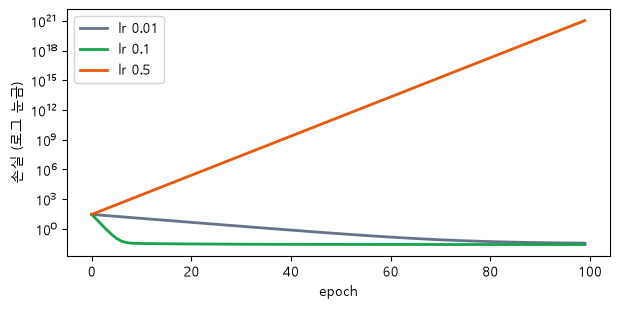

In [25]:
# 6단계: 학습률별 손실 경로 그래프 (발산이 함께 보이도록 로그 눈금)
# 왜 · 크기가 크게 다른 손실을 한 그래프에서 비교하기 위해
import matplotlib.pyplot as plt                # 그래프
plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False     # 음수 기호 깨짐 방지
plt.rcParams["font.size"] = 10                 # 본문 10pt

colors = {0.01: "#64748b", 0.1: "#16a34a", 0.5: "#ea580c"}   # 느림 회색 · 적절 초록 · 발산 주황
fig, ax = plt.subplots(figsize=(7, 3.2))                     # 그림 한 장
for lr, hist in results.items():                             # 학습률마다 선 하나
    ax.plot(hist, color=colors[lr], lw=2, label=f"lr {lr}")  # epoch별 손실
ax.set_yscale("log")                                         # 0.03과 1e+21을 한 그림에
ax.set_xlabel("epoch")                                       # 가로축
ax.set_ylabel("손실 (로그 눈금)")                            # 세로축
ax.legend(loc="upper left")                                  # 범례
plt.show()                                                   # 그리기

**결과** · 예측 정답은 `0.1` (손실 0.0266) — 0.5는 줄지 않고 **발산**(29 → 1.08e+21)

- `X: (100, 1) | Y: (100, 1) | 첫 샘플: 1.7645 7.4218` — 예측 `(100, 1)`과 1:1로 비교하도록 정답도 `(100, 1)`
- `최소제곱 해: w 2.954 · b 2.046` — 잡음 때문에 3 · 2와 조금 다름 → 경사하강이 도착해야 할 곳
- `lr 0.01 | w 2.789 | b 2.191 | loss 29 → 11.5 → 0.322 → 0.0368` — **느림** · 매번 줄지만 100번 뒤에도 덜 도착
- `lr 0.1 | w 2.945 | b 2.056 | loss 29 → 0.0338 → 0.0271 → 0.0266` — **적절** · 10번 만에 거의 도착
- `lr 0.5 | w -2.119e+10 | b -1.741e+10 | loss 29 → 2.74e+03 → 2.22e+11 → 1.08e+21` — **발산** · 점점 멀어짐
- `lr 0.01 | 매번 감소 True | 마지막/처음 0.00127` — 손실이 처음의 약 0.1%로
- `lr 0.1 | 매번 감소 True | 마지막/처음 0.000917` — 가장 많이 줄어듦
- `lr 0.5 | 매번 감소 False | 마지막/처음 3.72e+19` — 처음보다 엄청나게 커짐
- 그래프 — 로그 눈금이라 회색(느림) · 초록(적절)은 내려가고, 주황(발산)은 직선처럼 올라감

**학습률 3가지 비교**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">lr</th><th style="text-align: left;">경로</th><th style="text-align: left;">도착점 (w · b)</th><th style="text-align: left;">판정</th></tr>
</thead>
<tbody>
<tr><td><code>0.01</code></td><td>매번 감소, 100번 뒤 0.0368</td><td>2.789 · 2.191 (아직 이동 중)</td><td>느림 → epoch를 늘리거나 학습률을 키움</td></tr>
<tr><td><code>0.1</code></td><td>10번 만에 0.0338, 끝 0.0266</td><td>2.945 · 2.056 (최소제곱 해 근처)</td><td><strong>적절</strong></td></tr>
<tr><td><code>0.5</code></td><td>첫 걸음부터 증가, 끝 1.08e+21</td><td>-2.119e+10 · -1.741e+10</td><td>발산 → 학습률을 줄임</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 발산하면 값이 `inf` · `nan`이 되어 에러 없이 학습이 망가짐
> - 손실을 매번 기록하고 처음보다 커지면 학습률부터 낮추기

> ✅ **한 줄 정리** · 같은 기울기라도 학습률이 작으면 느리고 크면 발산하므로, 손실 경로 전체를 보고 학습률을 정한다.

**딥러닝 코드에서는**

- 딥러닝기초-2에서 이 실습의 `train()`이 아래처럼 바뀜
- 같은 단계를 `nn.Module` · `optimizer`가 대신 관리

```python
model = nn.Linear(1, 1).to(device)                       # w, b → 모델 파라미터
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)  # 학습률
for epoch in range(100):
    loss = F.mse_loss(model(X), Y)                       # 예측 → 손실
    optimizer.zero_grad()                                # grad.zero_()
    loss.backward()                                      # 기울기
    optimizer.step()                                     # no_grad 업데이트
```

### 8장 더 알아보기 · 방법별 차이

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>경사하강 (이번 실습)</td><td>기울기를 보고 <strong>조금씩</strong> 이동, 학습률이 필요</td><td>파라미터가 많은 모든 딥러닝 모델</td></tr>
<tr><td>최소제곱 해 <code>linalg.solve</code></td><td>식 하나로 <strong>바로</strong> 정답, 선형 모델에서만</td><td>선형 회귀 검산 · 작은 데이터</td></tr>
<tr><td>마지막 손실만 보기</td><td>도착 여부만 앎</td><td>빠른 확인</td></tr>
<tr><td>손실 경로 전체 보기</td><td>느림 · 적절 · 발산을 <strong>구분</strong></td><td>학습률을 정할 때 (기본 선택)</td></tr>
<tr><td>손실 그래프 로그 눈금</td><td>0.03과 1e+21을 한 그림에</td><td>값의 크기가 크게 다를 때</td></tr>
</tbody></table>

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 퍼셉트론 · 학습 아이디어</td><td><code>w = [1, 1]</code>에서 b만 -1.5 → -0.5로 바꿔 AND → OR, w = 3에서 cost를 줄이려면 키움</td><td>1-1 · 1-2</td></tr>
<tr><td>2. 텐서 읽기 · 모양 바꾸기</td><td><code>.T</code> 뒤 <code>view</code>는 에러 · <code>reshape</code>는 성공, <code>squeeze()</code>가 배치 축까지 지우는 것을 확인</td><td>2장 · 3장</td></tr>
<tr><td>3. shape 계약</td><td><code>(3, 1) - (3,)</code> → <code>(3, 3)</code>과 손실 1.3333을 찾아 <code>unsqueeze(1)</code>로 0.0</td><td>4-1 · 4-2</td></tr>
<tr><td>4. autograd</td><td><code>w.grad</code> -13이 양옆 계산과 같고, 비우지 않으면 -12 → -24로 누적</td><td>6장 · 7-1</td></tr>
<tr><td>5. 경사하강 · 학습률</td><td>직접 짠 루프로 w → 2 · b → 1, 0.01 느림 · 0.1 적절 · 0.5 발산</td><td>7장 · 8장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>퍼셉트론</td><td>가중합 <code>w·x + b</code> → 활성화</td><td><code>nn.Linear</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>학습 아이디어</td><td>손실이 줄어드는 쪽으로 조금씩</td><td><code>loss.backward()</code> → <code>step()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>텐서 만들기</td><td>값 <code>tensor</code> · 틀 <code>zeros</code> · 난수 <code>randn</code> + seed</td><td><code>torch.manual_seed(42)</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>shape · dtype · device</td><td>축 의미까지 읽기, 회귀 float32 · 분류 정답 int64, 같은 장치</td><td><code>x.to(device)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>NumPy ↔ 텐서</td><td><code>tensor</code> 복사 · <code>from_numpy</code> 공유, float32로</td><td><code>torch.from_numpy(a).float()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>인덱싱</td><td>NumPy와 같음, 원소 하나는 <code>item()</code>, 축은 <code>dim</code></td><td><code>loss.item()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>view · reshape</td><td>막히면 <code>reshape</code>, 축 교환은 <code>.T</code> · <code>permute</code></td><td><code>x.view(x.size(0), -1)</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>squeeze · unsqueeze</td><td>항상 <code>dim</code> 지정</td><td><code>img.unsqueeze(0)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>cat · stack</td><td>기존 축 · 새 축</td><td>배치 = <code>stack</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>broadcasting 함정</td><td>손실 직전 shape 같게</td><td><code>y.unsqueeze(1)</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>행렬 곱</td><td><code>[배치, 입력] @ [입력, 출력]</code></td><td><code>x @ W.T + b</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>MSE</td><td>차이 → 제곱 → 평균</td><td><code>nn.MSELoss()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>autograd</td><td><code>backward</code>는 기울기만, <code>.grad</code> 누적 → 비우기</td><td><code>optimizer.zero_grad()</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>업데이트</td><td><code>no_grad</code> 안에서 <code>w -= lr * w.grad</code></td><td><code>optimizer.step()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>학습률</td><td>작으면 느림 · 크면 발산, 경로로 판단</td><td><code>lr=1e-3</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>종합</td><td>같은 조건에서 학습률만 바꿔 경로 비교</td><td>학습률 탐색</td></tr>
<tr><td style="text-align: center;"><code>B</code></td><td>처음 보는 코드</td><td>이름이 아니라 역할 순서로</td><td>남의 학습 코드 읽기</td></tr>
</tbody></table>

---
## 기억 확인 문제

- 위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교
- ○ (정확) · △ (일부) · × (모름)를 표시하고, △ · ×인 섹션만 다시 보기
- 섹션 칸에 `자기 말`이 붙은 6개 = 강의 Closing "자기 말 설명" · 원본 P14 후반과 같은 질문

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · 퍼셉트론은 입력을 어떻게 0 · 1 판단으로 바꾸는가?
- **2-2 `자기 말`** · shape가 중요한 이유는? 숫자 말고 무엇을 함께 읽는가?
- **2-4** · `torch.tensor`와 `from_numpy`의 차이는?
- **3-2** · `view`와 `reshape`는 언제 다른가?
- **3-3** · `squeeze()`를 `dim` 없이 쓰면 무엇이 위험한가?
- **3-4** · `cat`과 `stack`은 어떻게 고르는가?
- **4-1 `자기 말`** · 실행됐지만 의도한 계산이 아닐 수 있는 예는?
- **4-2** · `*`와 `@`의 차이와 `[배치, 입력] @ [입력, 출력]`의 결과 shape는?
- **5-2** · MSE는 어떻게 계산하고, 무엇을 숨기는가?
- **6-2 `자기 말`** · `backward()`가 하는 일과 하지 않는 일은?
- **6-3 `자기 말`** · 기울기를 비우는 이유와, 매 단계 새 forward가 필요한 이유는?
- **7-1 `자기 말`** · 파라미터가 실제로 바뀌는 순간은? `no_grad`와 `detach`의 차이는?
- **7-3 `자기 말`** · 학습률을 마지막 손실 하나가 아니라 경로로 봐야 하는 이유는?
- **8** · 학습률 0.01 · 0.1 · 0.5의 결과는 각각 어땠는가?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `torch.arange(6).reshape(2, 3)`의 `.T`를 1차원으로 펼치기 (`view`가 안 되는 이유도 생각)
2. 예측 `(4, 1)` = [1, 2, 3, 4] · 정답 `(4,)` = [1, 2, 3, 5]의 MSE를 **올바른 짝으로** 계산
3. `y = x³`에서 `x = 2`의 기울기를 autograd로 구하기
4. `(3, 28, 28)` 이미지 텐서 4개를 배치 하나로 묶어 shape 출력
5. `y = 4x - 1` 위의 점 3개(x = 0, 1, 2)로 w · b를 0에서 시작해 학습률 0.1로 200번 학습

In [26]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 7-2 학습 루프를 학습률 **0.05**로 바꾸면 21번 뒤 w · b는 0.1일 때보다 정답(2, 1)에 가까울까? 예측 → 실행
2. 4-1에서 정답이 아니라 **예측 쪽**을 고쳐 1:1 비교를 만들기 (`squeeze`를 어디에 쓰나?)
3. 8장 `train()`에 학습률 **0.4 · 0.45**를 넣고 "매번 감소" · "마지막/처음"으로 판정하기

In [27]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 입력 × 가중치를 더하고 편향을 더한 뒤(`w·x + b`), 활성화 함수(계단)가 0보다 크면 1
- **2-2** · 연산이 shape로 짝을 정하기 때문. 각 축의 의미(샘플 · 채널 · 특성)를 함께 읽음
- **2-4** · `tensor`는 복사, `from_numpy`는 메모리 공유 (원본을 바꾸면 같이 바뀜)
- **3-2** · `.T` 뒤처럼 메모리가 연속이 아니면 `view`는 에러, `reshape`는 복사해서 성공
- **3-3** · 길이 1인 축이 전부 사라져 배치 1장의 배치 축까지 없어짐
- **3-4** · 기존 축을 늘리면 `cat`, 같은 모양을 묶는 새 축이 필요하면 `stack`
- **4-1** · 예측 `(N, 1)` - 정답 `(N,)` → `(N, N)` 모든 조합 비교 → 틀린 손실이 에러 없이 나옴
- **4-2** · `*`는 같은 위치 곱, `@`는 행 × 열 곱의 합. `[배치, 출력]`
- **5-2** · 차이 → 제곱 → 평균. 샘플별 오차 패턴(누가 얼마나 틀렸나)을 숨김
- **6-2** · 기울기를 계산해 `.grad`에 저장함. 파라미터 값은 바꾸지 않음
- **6-3** · `.grad`는 누적되므로 비움. 첫 backward가 계산 기록을 지우고 값도 바뀌었으므로 새 forward
- **7-1** · `no_grad` 안의 `w -= lr * w.grad`. `no_grad`는 블록 전체, `detach`는 텐서 하나
- **7-3** · 첫 걸음만 줄고 뒤에 발산하거나, 매번 줄지만 너무 느릴 수 있어서
- **8** · 0.01 느림 · 0.1 적절(최소제곱 해 근처) · 0.5 발산

#### 코드 문제 답

```python
# 1. .T 뒤에는 메모리가 끊김 → view 대신 reshape
t = torch.arange(6).reshape(2, 3)
print(t.T.reshape(-1).tolist())  # [0, 3, 1, 4, 2, 5]

# 2. 정답에 축 추가 → (4, 1) 끼리 1:1 비교
pred = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
target = torch.tensor([1.0, 2.0, 3.0, 5.0])
print(F.mse_loss(pred, target.unsqueeze(1)).item())  # 0.25

# 3. requires_grad → 계산 → backward → .grad (3x² = 12)
x = torch.tensor(2.0, requires_grad=True)
(x ** 3).backward()
print(x.grad.item())  # 12.0

# 4. 같은 모양 4개 → 새 배치 축으로 stack
imgs = [torch.zeros(3, 28, 28) for _ in range(4)]
print(tuple(torch.stack(imgs).shape))  # (4, 3, 28, 28)

# 5. 예측 → 손실 → backward → no_grad 업데이트 → zero_
X3 = torch.tensor([[0.], [1.], [2.]])
Y3 = 4 * X3 - 1
w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
for _ in range(200):
    loss = F.mse_loss(X3 * w + b, Y3)
    loss.backward()
    with torch.no_grad():
        w -= 0.1 * w.grad
        b -= 0.1 * b.grad
    w.grad.zero_()
    b.grad.zero_()
print(round(w.item(), 2), round(b.item(), 2))  # 4.0 -1.0
```

#### 변형 문제 답

*문제 → 답*

- **1** · 덜 가까움 · w 2.0129 · b 0.9725 (0.1이면 2.0067 · 0.9857) → 같은 횟수면 보폭이 작은 쪽이 덜 도착
- **2** · `pred_col.squeeze(1) - target3` → `(3,)` · 손실 0.0 (예측 `(N, 1)` → `(N,)`)
- **3** · 0.4 = 매번 감소 False(출렁임)지만 마지막/처음 0.000916으로 수렴 · 0.45 = 349배로 발산 → 경계는 그 사이

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) <code>backward()</code> 뒤 w가 바뀐다고 답함</td><td>기울기 계산과 업데이트를 섞음</td><td>값은 <code>no_grad</code> 안의 <code>-=</code>에서 바뀜</td><td>이 줄은 기울기만 구하나, 값을 바꾸나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. PyTorch 텐서와 NumPy 배열의 차이는?**
> - 모양 규칙과 인덱싱
> - broadcasting은 거의 같지만, 텐서는 GPU에서 계산할 수 있고 `requires_grad=True`로 계산 기록을 남겨 `backward()`로 기울기를 자동 계산합니다.
> - 변환은 `torch.from_numpy`가 메모리를 공유하고 `torch.tensor`는 복사하며, NumPy 기본 float64를 모델용 float32로 맞추는 것에 주의합니다.

**Q2. `view`와 `reshape`의 차이는?**
> - 둘 다 원소 수를 유지하며 모양을 바꾸지만, `view`는 메모리가 연속일 때만 복사 없이 같은 메모리를 보여 주고, 전치 뒤처럼 연속이 아니면 에러가 납니다.
> - `reshape`는 가능하면 view처럼 동작하고 안 되면 복사해서라도 결과를 만들어 줍니다.
> - 축의 의미를 바꾸는 것은 `transpose`나 `permute`입니다.

**Q3. `loss.backward()`는 무엇을 하고, 왜 `zero_grad()`가 필요한가요?**
> - `backward()`는 forward 때 기록된 계산 그래프를 거꾸로 따라가 각 파라미터의 기울기를 `.grad`에 저장할 뿐, 파라미터 값은 바꾸지 않습니다.
> - `.grad`는 덮어쓰지 않고 누적되므로, 매 단계 `zero_grad()`로 비우지 않으면 이전 배치의 기울기가 섞여 잘못된 방향으로 업데이트됩니다.

**Q4. `torch.no_grad()`는 언제 쓰고, `detach()`와 무엇이 다른가요?**
> - 블록 안의 모든 연산을 계산 그래프에 기록하지 않게 하므로, 파라미터를 직접 업데이트할 때와 검증
> - 추론에서 메모리와 시간을 아끼려고 씁니다.
> - `detach()`는 텐서 하나를 그래프에서 떼어 낸 새 텐서를 돌려주는 것이라, 특정 값만 기록 없이 넘길 때 씁니다.

**Q5. 학습률이 너무 크거나 작으면 어떻게 되나요?**
> - 기울기는 방향만 알려 주고 실제 이동 크기는 학습률 × 기울기입니다.
> - 너무 작으면 손실이 매번 줄지만 느려서 정해진 epoch 안에 수렴하지 못하고, 너무 크면 최저점을 지나쳐 손실이 오히려 커지며 발산해 `nan`이 됩니다.
> - 그래서 마지막 손실만이 아니라 손실 경로 전체를 보고 학습률을 정합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>X @ w + b</code> · <code>&gt; 0</code> · <code>.int()</code></td><td>torch 연산 · 텐서 메서드</td><td>가중합 · 계단 함수 · 정수 변환</td><td>1-1 <code>h = X @ w + b</code></td></tr>
<tr><td><code>(예측 - 정답) ** 2</code></td><td>torch 연산</td><td>제곱 오차 (cost)</td><td>1-2 <code>cost = (w_cands * x_one - y_one) ** 2</code></td></tr>
<tr><td><code>argmin()</code> · <code>item()</code> · <code>tolist()</code></td><td>텐서 메서드</td><td>최소 위치 · 숫자 · 리스트로 꺼내기</td><td>1-2 <code>print("cost 최소 w:", w_cands[cost.argmin()].item())</code></td></tr>
<tr><td><code>torch.tensor()</code> · <code>zeros()</code> · <code>ones()</code> · <code>arange()</code></td><td>torch</td><td>값 지정 · 0 · 1 · 수열로 만들기</td><td>2-1 <code>vec = torch.tensor([10, 20, 30, 40])</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>rand()</code> · <code>randn()</code> · <code>manual_seed()</code></td><td>torch</td><td>균등 · 정규 난수 · seed 고정</td><td>2-1 <code>noise = torch.randn(2, 2)</code></td></tr>
<tr><td><code>.shape</code> · <code>.size()</code> · <code>.ndim</code> · <code>.numel()</code></td><td>텐서 속성 · 메서드</td><td>모양 · 축 개수 · 원소 수</td><td>2-2 <code>t.ndim</code> · <code>images.size()</code> · <code>images.numel()</code></td></tr>
<tr><td><code>.dtype</code> · <code>.float()</code> · <code>.to(device)</code></td><td>텐서 속성 · 메서드</td><td>종류 확인 · 실수 변환 · 장치 이동</td><td>2-3 <code>labels.float()</code> · <code>probs.to(device)</code></td></tr>
<tr><td><code>torch.device()</code> · <code>cuda.is_available()</code></td><td>torch</td><td>실행 장치 정하기</td><td>0 <code>torch.device("cuda" if torch.cuda.is_available() else "cpu")</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>from_numpy()</code> · <code>.numpy()</code> · <code>.item()</code> · <code>.tolist()</code></td><td>torch · 텐서 메서드</td><td>NumPy ↔ 텐서 · 숫자 · 리스트</td><td>2-4 <code>t_share = torch.from_numpy(arr)</code></td></tr>
<tr><td><code>t[i, j]</code> · <code>t[a:b]</code> · <code>t[mask]</code></td><td>인덱싱 (NumPy와 같음)</td><td>위치 · 구간 · 조건으로 꺼내기</td><td>3-1 <code>base[1:3, 1:4]</code> · <code>weather[weather[:, 2] == 1]</code></td></tr>
<tr><td><code>mean(dim=)</code></td><td>텐서 메서드</td><td>축 방향 계산 (<code>axis</code> 대신 <code>dim</code>)</td><td>3-1 <code>print("열 평균(dim=0):", weather.mean(dim=0).tolist())</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>view()</code> · <code>reshape()</code> · <code>.T</code> · <code>is_contiguous()</code></td><td>텐서 메서드 · 속성</td><td>모양 바꾸기 · 축 교환 · 메모리 연속 확인</td><td>3-2 <code>grid.view(2, 6)</code> · <code>grid.T.reshape(12)</code> · <code>grid.T.is_contiguous()</code></td></tr>
<tr><td><code>squeeze()</code> · <code>unsqueeze()</code></td><td>텐서 메서드</td><td>길이 1 축 제거 · 추가</td><td>3-3 <code>col = target4.unsqueeze(1)</code></td></tr>
<tr><td><code>torch.cat()</code> · <code>torch.stack()</code></td><td>torch</td><td>기존 축 잇기 · 새 축 쌓기</td><td>3-4 <code>torch.cat([a, b], dim=0)</code> · <code>torch.stack([a, b], dim=0)</code></td></tr>
<tr><td><code>torch.equal()</code></td><td>torch</td><td>모양 · 값이 모두 같은가</td><td>3-2 <code>print("같은가:", torch.equal(grid.reshape(4, 3), grid…</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>-</code> · <code>+</code> (broadcasting)</td><td>torch 연산</td><td>모양이 달라도 늘려서 계산</td><td>4-1 <code>wrong = pred_col - target3</code></td></tr>
<tr><td><code>assert a.shape == b.shape</code></td><td>Python 기본 문법</td><td>모양이 다르면 바로 멈춤</td><td>4-1 <code>assert pred_col.shape == target3.unsqueeze(1).shape</code></td></tr>
<tr><td><code>*</code> · <code>@</code> · <code>torch.matmul()</code></td><td>torch 연산 · torch</td><td>원소별 곱 · 행렬 곱</td><td>4-2 <code>left * same</code> · <code>left @ weight</code> · <code>torch.matmul(left, weight)</code></td></tr>
<tr><td><code>RuntimeError</code></td><td>Python 예외</td><td>shape · 메모리 · 기록 관련 실행 오류</td><td>3-2 <code>except RuntimeError:</code> (<code>grid.T.view(12)</code> 실패)</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>w * x + b</code></td><td>torch 연산</td><td>선형 모델 예측</td><td>5-1 <code>w_v * x_in + b_v</code></td></tr>
<tr><td><code>** 2</code> · <code>.mean()</code> · <code>.abs()</code></td><td>torch 연산 · 텐서 메서드</td><td>제곱 · 평균 · 절댓값 (MSE · MAE)</td><td>5-2 <code>squared = error ** 2</code></td></tr>
<tr><td><code>F.mse_loss()</code></td><td>torch.nn.functional</td><td>MSE 손실 함수</td><td>5-2 <code>print("F.mse_loss:", F.mse_loss(pred3, true3).item…</code></td></tr>
<tr><td><code>requires_grad=True</code></td><td>torch.tensor 인자</td><td>계산 기록 시작 (파라미터 표시)</td><td>6-2 <code>x9 = torch.tensor(3.0, requires_grad=True)</code></td></tr>
<tr><td><code>.backward()</code></td><td>텐서 메서드</td><td>기울기 계산 → <code>.grad</code></td><td>6-2 <code>loss.backward()</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>.grad</code> · <code>.grad_fn</code> · <code>.requires_grad</code></td><td>텐서 속성</td><td>기울기 · 만든 연산 · 기록 여부</td><td>6-2 <code>w.grad.item()</code> · <code>loss.grad_fn</code> · <code>x_train.requires_grad</code></td></tr>
<tr><td><code>.grad.zero_()</code></td><td>텐서 메서드</td><td>기울기 비우기 (제자리 수정)</td><td>6-3 <code>w.grad.zero_()</code></td></tr>
<tr><td><code>with torch.no_grad():</code></td><td>torch · Python <code>with</code></td><td>블록 안 계산을 기록하지 않음</td><td>7-1 <code>with torch.no_grad():</code></td></tr>
<tr><td><code>w -= lr * w.grad</code></td><td>torch 연산 (제자리)</td><td>기울기 반대 방향으로 이동</td><td>7-1 <code>w -= lr * w.grad</code></td></tr>
<tr><td><code>.detach()</code> · <code>.item()</code></td><td>텐서 메서드</td><td>기록 없는 텐서 · Python 숫자</td><td>7-1 <code>out_detach = (t * 2).detach()</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>for step in range(n):</code></td><td>Python 기본 문법</td><td>학습 반복</td><td>7-2 <code>for step in range(21):</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>손실 직전 <code>assert pred.shape == y.shape</code></td><td><code>(N, 1) - (N,)</code> 그대로 빼기</td></tr>
<tr><td>매 단계 기울기 비우기</td><td>같은 loss로 <code>backward()</code> 두 번</td></tr>
<tr><td>업데이트는 <code>no_grad</code> 안에서</td><td><code>requires_grad</code> 텐서를 그냥 <code>-=</code></td></tr>
<tr><td>기록은 <code>loss.item()</code></td><td>텐서째 리스트에 모으기</td></tr>
<tr><td><code>squeeze(dim)</code> · <code>unsqueeze(dim)</code></td><td><code>dim</code> 없는 <code>squeeze()</code></td></tr>
<tr><td>모델 · 데이터를 같은 <code>device</code>로</td><td>NumPy float64를 그대로 모델에</td></tr>
<tr><td>손실 경로 전체로 학습률 판단</td><td>마지막 손실 하나로 판단</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td><code>torch.tensor</code> vs <code>from_numpy</code></td><td>복사 vs 메모리 공유</td><td>보통 <code>tensor</code>, 큰 배열 빠르게는 <code>from_numpy</code></td></tr>
<tr><td><code>view</code> vs <code>reshape</code></td><td>공유만 · 연속일 때만 vs 안 되면 복사</td><td>보통 <code>reshape</code></td></tr>
<tr><td><code>reshape</code> vs <code>.T</code></td><td>순서대로 다시 채움 vs 축 순서 교환</td><td>축 의미를 바꿀 땐 <code>.T</code> · <code>transpose</code></td></tr>
<tr><td><code>squeeze</code> vs <code>unsqueeze</code></td><td>길이 1 축 제거 vs 추가</td><td>항상 <code>dim</code>을 지정</td></tr>
<tr><td><code>cat</code> vs <code>stack</code></td><td>기존 축 늘리기 vs 새 축 만들기</td><td>샘플 → 배치는 <code>stack</code></td></tr>
<tr><td><code>*</code> vs <code>@</code> vs <code>matmul</code></td><td>같은 위치 곱 vs 행렬 곱 vs <code>@</code>와 동일</td><td>층 계산은 <code>@</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td><code>(N, 1)</code> vs <code>(N,)</code></td><td>열 모양 vs 1차원</td><td>빼기 전에 모양을 같게</td></tr>
<tr><td>손실 vs 기울기</td><td>얼마나 틀렸나 vs 어느 쪽으로 고칠까</td><td>둘 다 매 단계 새로 계산</td></tr>
<tr><td><code>backward()</code> vs 업데이트</td><td>기울기 계산만 vs 값을 실제로 바꿈</td><td><code>no_grad</code> 안의 <code>-=</code>에서 바뀜</td></tr>
<tr><td>누적 vs <code>grad.zero_()</code></td><td>기울기가 더해짐 vs 0으로 비움</td><td>매 단계 비우기</td></tr>
<tr><td><code>no_grad</code> vs <code>detach</code></td><td>블록 전체 vs 텐서 하나</td><td>업데이트 · 평가는 <code>no_grad</code></td></tr>
<tr><td><code>detach</code> vs <code>item</code></td><td>기록 없는 텐서 vs Python 숫자</td><td>기록 · 출력은 <code>item</code></td></tr>
<tr><td>작은 lr vs 큰 lr</td><td>느림 vs 지나쳐서 발산</td><td>손실 경로 전체를 보고 정하기</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개를 새로 풀기 · 학습 한 바퀴 그림(7장)을 가리고 다섯 단계를 코드로 적기</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>8장 <code>train()</code>을 빈 셀에 직접 다시 짜고 학습률 3가지 결과를 먼저 예측한 뒤 실행</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제만 · 딥러닝기초-2 시작 전 4 · 6 · 7장 ✅ 줄만 읽기</td><td>15분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 딥러닝 개론 PDF(퍼셉트론 · 손실 · 경사), PyTorch Day01 강의, Day01 연습문제(P01 ~ P14, P15 포함)를 중복 없이 7개 대단원
- 21개 섹션으로 재구성하고, 8장 종합 실습(직접 만든 선형 회귀 · 학습률 3가지 비교)으로 연결.
- 연습문제는 빈칸 문제판이라 정답 코드를 직접 작성해 실행으로 검증함.
- NumPy와 겹치는 인덱싱
- broadcasting은 차이점만 다룸(03 NumPy 정리본 참조).

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">연습문제</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td>개론 PDF 4~6쪽 뉴런 · 퍼셉트론 · AND/OR</td><td>—</td><td>1-1</td></tr>
<tr><td>개론 PDF 7쪽 경사하강 + 강의 Prelude</td><td>—</td><td>1-2</td></tr>
<tr><td>강의 §1 Tensor 만들기 · shape · dtype · device</td><td>P01 · P15</td><td>2-1 · 2-2 · 2-3</td></tr>
<tr><td>강의 §3 NumPy와 최소 연결</td><td>—</td><td>2-4</td></tr>
<tr><td>강의 §2 원하는 부분 선택</td><td>P02</td><td>3-1 (NumPy와 <strong>차이점만</strong>)</td></tr>
<tr><td>강의 §3 reshape · transpose · squeeze · cat/stack</td><td>P03 · P04</td><td>3-2 · 3-3 · 3-4 (P03은 view와 squeeze로 <strong>분할</strong>)</td></tr>
<tr><td>강의 §4 broadcasting 침묵 실패</td><td>P05 · P08 후반</td><td>4-1 (<strong>통합</strong>: 같은 함정이라 1회)</td></tr>
<tr><td>강의 §4~5 <code>*</code> · <code>@</code> · 행렬 곱 shape 계약</td><td>P06</td><td>4-2</td></tr>
<tr><td>강의 §6 가장 작은 모델 · §7 MSE</td><td>P07 · P08</td><td>5-1 · 5-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">연습문제</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td>강의 §8 국소 기울기 · autograd · 누적</td><td>P09 · P10</td><td>6-1 · 6-2 · 6-3</td></tr>
<tr><td>강의 §9 수동 update · no_grad · 반복 · 코드 읽기</td><td>P11 · P12 · P14</td><td>7-1 · 7-2 · 7-4</td></tr>
<tr><td>강의 §10 학습률</td><td>P13</td><td>7-3 · 8 (<strong>통합</strong>: 강의의 학습률 경로 비교는 직접 만든 데이터로 8장에서 1회)</td></tr>
<tr><td>강의 Closing 자기 말 설명 6문장</td><td>P14 후반</td><td>9-1 백지 복습</td></tr>
<tr><td>개론 PDF 8~9쪽 XOR · 다층</td><td>—</td><td>딥러닝기초-2 (1-1 주의에서 예고)</td></tr>
</tbody></table>

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">순서</th><th style="text-align: left;">배우는 이유</th><th style="text-align: left;">대단원</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">1</td><td>모델은 가중합이고, 학습은 틀린 쪽의 반대로 고치는 것이다</td><td>퍼셉트론과 학습 아이디어</td></tr>
<tr><td style="text-align: center;">2</td><td>그 계산을 하려면 데이터 · 가중치를 텐서에 담아야 한다</td><td>텐서 만들기 · 읽기</td></tr>
<tr><td style="text-align: center;">3</td><td>담은 텐서를 꺼내고 모델이 받는 모양으로 바꾼다</td><td>꺼내기 · 모양 바꾸기</td></tr>
<tr><td style="text-align: center;">4</td><td>모양이 맞아야 계산이 의도대로 된다</td><td>계산과 shape 계약</td></tr>
<tr><td style="text-align: center;">5</td><td>계산으로 예측을 만들고 틀린 정도를 잰다</td><td>예측과 손실</td></tr>
<tr><td style="text-align: center;">6</td><td>손실을 줄이는 방향(기울기)을 자동으로 구한다</td><td>기울기 · autograd</td></tr>
<tr><td style="text-align: center;">7</td><td>기울기로 값을 바꾸고 반복한다</td><td>경사하강</td></tr>
<tr><td style="text-align: center;">8</td><td>1~7을 직접 만든 데이터 한 번에 쓴다</td><td>종합 실습</td></tr>
</tbody></table>

#### 학습 한 바퀴 · 이 권 전체가 설명하는 반복

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">순서</th><th style="text-align: left;">코드</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">1</td><td><code>pred = w * x + b</code></td><td>지금 파라미터로 예측</td><td>5-1</td></tr>
<tr><td style="text-align: center;">2</td><td><code>loss = ((pred - y) ** 2).mean()</code></td><td>틀린 정도를 숫자 하나로</td><td>4-1 · 5-2</td></tr>
<tr><td style="text-align: center;">3</td><td><code>loss.backward()</code></td><td>기울기 계산 → <code>.grad</code> (값은 그대로)</td><td>6-1 · 6-2</td></tr>
<tr><td style="text-align: center;">4</td><td><code>with torch.no_grad(): w -= lr * w.grad</code></td><td>실제로 값을 바꿈</td><td>7-1 · 7-3</td></tr>
<tr><td style="text-align: center;">5</td><td><code>w.grad.zero_()</code></td><td>다음 단계를 위해 기울기 비우기</td><td>6-3</td></tr>
<tr><td style="text-align: center;">6</td><td>1번으로</td><td>바뀐 값으로 새 예측</td><td>7-2 · 8</td></tr>
</tbody></table>

#### ML/DL 공통 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰이는 장</th></tr>
</thead>
<tbody>
<tr><td>① 데이터 준비</td><td>데이터를 텐서로 만들기, seed 고정</td><td>2장 · <strong>8장</strong></td></tr>
<tr><td>② 불러오기</td><td>샘플을 배치로 묶기 (<code>stack</code>)</td><td>3장 (DataLoader는 딥러닝기초-2)</td></tr>
<tr><td>③ 전처리</td><td>dtype · 장치 · 모양 맞추기</td><td>2장 · 3장 · <strong>8장</strong></td></tr>
<tr><td>④ 모델</td><td>가중합 <code>wx + b</code>, 행렬 곱 <code>X @ W</code></td><td>1장 · 4장 · 5장</td></tr>
<tr><td>⑤ 학습</td><td>손실 → 기울기 → 업데이트 반복</td><td>5장 ~ 7장 · <strong>8장</strong></td></tr>
<tr><td>⑥ 평가</td><td>손실 경로 비교, 정답 규칙과 비교</td><td>7장 · <strong>8장</strong></td></tr>
<tr><td>⑦ 저장 · 기록</td><td>손실 기록 <code>item()</code></td><td>3장 · <strong>8장</strong> (모델 저장은 딥러닝기초-2)</td></tr>
</tbody></table>

**굵은 8장** · 종합 실습이 ① ③ ⑤ ⑥ ⑦ 을 한 번에 연결

### 전체 코드

1 ~ 8장 핵심 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며(GPU가 없으면 cpu), 각 출력 앞 `[번호]`가 섹션.

**실행 흐름**

1. 전체 코드 머리말 · 도구 불러오기
2. 아래 셀들을 위에서부터 차례로 실행

In [28]:
# ============================================================
# 딥러닝기초-1 텐서 · 경사하강 — 전체 코드
# 왜 · 본문을 다시 열지 않고도 이 셀들만으로 전체를 재현하기 위해
# ============================================================
import numpy as np               # NumPy 변환 비교 (2-4)
import torch                     # 텐서 · 자동 미분
import torch.nn.functional as F  # mse_loss

torch.manual_seed(0)  # 난수 기준값 고정 → 같은 환경에서 같은 결과
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # 쓸 장치 고르기

**실행 흐름**

1. 1-1 퍼셉트론 판정
2. 1-2 w 후보별 cost

In [29]:
# ---------- 1. 퍼셉트론과 학습 아이디어 ----------
# 1-1 가중합 → 계단 함수, AND · OR는 b만 다름
# 왜 · 퍼셉트론 판정을 다시 확인하기 위해
Xg = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
wg = torch.tensor([1.0, 1.0])                         # 두 입력 같은 무게
print("[1-1]", ((Xg @ wg - 1.5) > 0).int().tolist(),  # AND · OR = b만 다름
      ((Xg @ wg - 0.5) > 0).int().tolist())

# 1-2 w 후보마다 cost → 가장 작은 w
cands = torch.tensor([1.0, 3.0, 5.0, 7.0, 9.0])                 # w 후보
print("[1-2]", cands[((cands * 2 - 10) ** 2).argmin()].item())  # cost 최소 w

[1-1] [0, 0, 0, 1] [0, 1, 1, 1]
[1-2] 5.0


**실행 흐름**

1. 2-1 텐서 만들기
2. 2-2 크기 함수
3. 2-3 · 2-4 자료형 · NumPy 변환

In [30]:
# ---------- 2. 텐서 만들기 · 읽기 ----------
# 2-1 정수만 넣으면 int64, zeros(2, 3)은 괄호 없이
# 왜 · 텐서를 만드는 규칙을 다시 확인하기 위해
print("[2-1]", torch.tensor([10, 20]).dtype, tuple(torch.zeros(2, 3).shape))

# 2-2 shape · ndim · numel
img4 = torch.arange(24.0).reshape(2, 3, 2, 2)               # 샘플 · 채널 · 높이 · 너비
print("[2-2]", tuple(img4.shape), img4.ndim, img4.numel())  # 모양 · 축 수 · 원소 수

# 2-3 정수 × 실수 → float32
lab = torch.tensor([0, 1, 2])                                # 정수 → int64
print("[2-3]", (lab * torch.tensor([0.1, 0.8, 0.3])).dtype)  # 섞으면 float32

# 2-4 tensor()는 복사, from_numpy()는 메모리 공유
arr = np.array([1.5, 2.5])                         # 원본 배열
tc, ts = torch.tensor(arr), torch.from_numpy(arr)  # 복사 · 공유
arr[0] = 100.0                                     # 원본 배열만 수정
print("[2-4]", tc.tolist(), ts.tolist())           # 공유본만 바뀜

[2-1] torch.int64 (2, 3)
[2-2] (2, 3, 2, 2) 4 24
[2-3] torch.float32
[2-4] [1.5, 2.5] [100.0, 2.5]


**실행 흐름**

1. 3-1 꺼내기
2. 3-2 reshape · view · .T
3. 3-3 · 3-4 축 넣고 빼기 · cat vs stack

In [31]:
# ---------- 3. 꺼내기 · 모양 바꾸기 ----------
# 3-1 숫자 → 축 사라짐, 슬라이스 → 축 유지, 원소 하나는 item()
# 왜 · 꺼내는 방법에 따른 모양 변화를 다시 확인하기 위해
base = torch.arange(20).reshape(4, 5)                         # 0 ~ 19를 4행 5열로
print("[3-1]", tuple(base[2].shape), tuple(base[2:3].shape),  # 축 사라짐 · 유지
      base[0, 0].item())

# 3-2 .T 뒤 view 실패 · reshape 성공
grid = torch.arange(1, 13).reshape(3, 4)                                 # 1 ~ 12를 3행 4열로
print("[3-2]", grid.T.is_contiguous(), grid.T.reshape(12)[:4].tolist())  # .T 뒤는 reshape

# 3-3 unsqueeze 추가 · squeeze 제거
print("[3-3]", tuple(torch.zeros(4).unsqueeze(1).shape),  # 축 추가 · 제거
      tuple(torch.zeros(3, 1, 4).squeeze(1).shape))

# 3-4 cat 기존 축 · stack 새 축
a, b = torch.ones(2, 3), torch.zeros(2, 3)      # (2, 3) 두 개
print("[3-4]", tuple(torch.cat([a, b]).shape),  # 기존 축 · 새 축
      tuple(torch.stack([a, b]).shape))

[3-1] (5,) (1, 5) 0
[3-2] False [1, 5, 9, 2]
[3-3] (4, 1) (3, 4)
[3-4] (4, 3) (2, 2, 3)


**실행 흐름**

1. 4-1 브로드캐스팅 함정
2. 4-2 원소별 곱 vs 행렬 곱

In [32]:
# ---------- 4. 계산과 shape 계약 ----------
# 4-1 (3, 1) - (3,) → (3, 3) 함정, unsqueeze로 1:1
# 왜 · 브로드캐스팅 함정과 해결을 다시 확인하기 위해
pc = torch.tensor([[1.0], [2.0], [3.0]])                                     # 예측 (3, 1)
tg = torch.tensor([1.0, 2.0, 3.0])                                           # 정답 (3,)
print("[4-1]", tuple((pc - tg).shape), tuple((pc - tg.unsqueeze(1)).shape))  # 함정 · 1:1

# 4-2 * 원소별 · @ 행렬 곱 (= matmul)
left = torch.tensor([[1., 2., 3.], [4., 5., 6.]])      # 샘플 2 × 특성 3
weight = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])  # 입력 3 → 출력 2
print("[4-2]", (left @ weight).tolist())               # 행렬 곱

[4-1] (3, 3) (3, 1)
[4-2] [[4.0, 5.0], [10.0, 11.0]]


**실행 흐름**

1. 5-1 예측 변화
2. 5-2 MSE

In [33]:
# ---------- 5. 예측과 손실 ----------
# 5-1 w 변화는 x에 비례, b 변화는 모두 같음
# 왜 · 예측 변화 규칙을 다시 확인하기 위해
xs = torch.tensor([1.0, 2.0, 4.0])                                            # 입력 3개
print("[5-1]", (3 * xs - 2 * xs).tolist(), ((2 * xs + 1) - 2 * xs).tolist())  # w · b 변화량

# 5-2 MSE = 차이 → 제곱 → 평균
p52, t52 = torch.tensor([2., 4., 6.]), torch.tensor([3., 5., 4.])  # 예측 · 정답
print("[5-2]", F.mse_loss(p52, t52).item())                        # MSE

[5-1] [1.0, 2.0, 4.0] [1.0, 1.0, 1.0]
[5-2] 2.0


**실행 흐름**

1. 6-1 변화율
2. 6-2 backward
3. 6-3 기울기 누적 · 비우기

In [34]:
# ---------- 6. 기울기 · autograd ----------
x_train = torch.tensor([1.0, 2.0])  # 입력 2개
y_train = torch.tensor([3.0, 5.0])  # 정답 2개

# 6-2 backward → .grad 에 저장 (w, b 값은 그대로)
# 왜 · backward가 하는 일을 다시 확인하기 위해
w = torch.tensor(0.0, requires_grad=True)               # 학습할 값 → 기록 시작
b = torch.tensor(0.0, requires_grad=True)               # 편향도 기록
((w * x_train + b - y_train) ** 2).mean().backward()    # 손실 → 기울기
print("[6-2]", w.grad.item(), b.grad.item(), w.item())  # 기울기 · 값 그대로

# 6-3 비우지 않으면 누적 → zero_()
((w * x_train + b - y_train) ** 2).mean().backward()  # 비우지 않고 한 번 더
print("[6-3]", w.grad.item())                         # -13 + -13
w.grad.zero_()                                        # w 기울기만 0
b.grad.zero_()                                        # b 기울기만 0

[6-2] -13.0 -8.0 0.0
[6-3] -26.0


tensor(0.)

**실행 흐름**

1. 7-1 한 학습 단계
2. 7-2 반복 학습
3. 7-3 학습률 비교

In [35]:
# ---------- 7. 경사하강 ----------
# 7-2 예측 → 손실 → backward → no_grad 업데이트 → zero_
# 왜 · 학습 한 단계의 순서를 다시 실행하기 위해
X4 = torch.tensor([[0.], [1.], [2.], [3.]])        # 입력 (4, 1)
Y4 = 2 * X4 + 1                                    # 정답 규칙
w = torch.tensor(0.0, requires_grad=True)          # 학습할 값 → 기록 시작
b = torch.tensor(0.0, requires_grad=True)          # 편향도 기록
for step in range(21):                             # 21번 반복
    loss = ((w * X4 + b - Y4) ** 2).mean()         # 시작 손실
    loss.backward()                                # 거꾸로 따라가 .grad 채움
    with torch.no_grad():                          # 업데이트는 기록하지 않음
        w -= 0.1 * w.grad                          # 기울기 반대 방향
        b -= 0.1 * b.grad                          # b도 같은 규칙
    w.grad.zero_()                                 # w 기울기만 0
    b.grad.zero_()                                 # b 기울기만 0
print(f"[7-2] w {w.item():.4f} b {b.item():.4f}")  # 2 · 1에 가까운가

[7-2] w 2.0067 b 0.9857


**실행 흐름**

1. 데이터 만들기
2. 학습률 3가지로 학습
3. 경로 판정

In [36]:
# ---------- 8. 종합 실습 · 학습률 3가지 ----------
# 왜 · 학습률 비교 실습을 다시 실행하기 위해
torch.manual_seed(42)                                      # 같은 데이터를 매번
X = torch.rand(100, 1) * 2                                 # 0 ~ 2 입력 100개
Y = 3 * X + 2 + 0.2 * torch.randn(100, 1)                  # 정답 규칙 + 잡음
X, Y = X.to(device), Y.to(device)                          # 만든 뒤 장치로 → CPU · GPU 같은 데이터
for lr in [0.01, 0.1, 0.5]:                                # 작음 · 적절 · 큼
    w = torch.zeros(1, requires_grad=True, device=device)  # 같은 시작값 0
    b = torch.zeros(1, requires_grad=True, device=device)  # b도 0 · 같은 장치
    for epoch in range(100):                               # 100번
        loss = F.mse_loss(X * w + b, Y)                    # 예측 → 손실
        loss.backward()                                    # 거꾸로 따라가 .grad 채움
        with torch.no_grad():                              # 업데이트는 기록하지 않음
            w -= lr * w.grad                               # 이동 = lr × 기울기
            b -= lr * b.grad                               # 0 - 0.05 × (-6)
        w.grad.zero_()                                     # w 기울기만 0
        b.grad.zero_()                                     # b 기울기만 0
    print(f"[8] lr {lr:<4} w {w.item():.4g} b {b.item():.4g}")  # 느림 · 적절 · 발산

[8] lr 0.01 w 2.789 b 2.191
[8] lr 0.1  w 2.945 b 2.056
[8] lr 0.5  w -2.119e+10 b -1.741e+10
